# Diabetes Prediction Model (NHANES 2017–2018)

**Goal:** a screening model that flags adults likely to have diabetes using **only physical exam measurements** (body measures, blood pressure, pulse) plus age and sex. **No blood test of any kind** is needed to use it.

**Pipeline (one section per step):**

Each step lists the data it uses and its sub-steps. 🔁 marks a sub-step that **learns from data** (for example, a median or a mean). Those go inside a scikit-learn `Pipeline`, so they are refit on the training part of every CV fold and never see validation or test rows.

1. **Feature identification** ← *this section* · *all data*
   - 1.1–1.4 Load and join the raw tables
   - 1.5 Define the target
   - 1.6–1.7 Apply the cohort filters
   - 1.8–1.11 Feature catalog, leakage guard, final table preview
2. **Feature table** · *all data*
   - 2.1 Fix storage glitches (tiny floats like `5.4e-79` that are really 0)
   - 2.2 Diastolic BP of 0 means "not measurable" → missing
   - 2.3 Recode skipped questions (`taking_bp_meds`: blank means "no")
   - 2.4 Fix data types (e.g. `gender` is a category stored as 1.0/2.0)
   - 2.5 Sanity checks: one row per person, target is 0/1, values physically possible
   - 2.6 **Stratified 80/20 train/test split**; the test set is sealed from here on
   - 2.7 Check the split
3. **Exploratory data analysis (EDA)** · *train only*
   - 3.0 Plot setup
   - 3.1 Target balance
   - 3.2 Missing values per feature
   - 3.3 Distributions
   - 3.4 Outliers and impossible values
   - 3.5 Each feature vs the target
   - 3.6 Diabetic rate by sex and age group
   - 3.7 Single-feature ROC-AUC ranking
   - 3.8 Correlations and redundant features (e.g. BMI, weight and waist)
   - 3.9 Effect of blood pressure medication on readings
   - 3.10 Findings → Step 4 actions
4. **Feature preparation and engineering** · *rules decided on train*
   - 4.1 Impossible values: diastolic readings below 40 → missing
   - 4.2 Derived features: mean systolic and diastolic BP (replacing the separate readings), waist-to-height, waist-to-hip, leg-to-height ratios
   - 4.3 🔁 **Imputing** missing values with the median (no missing-value flags, see 3.2)
   - 4.4 🔁 **Encoding** categorical columns (e.g. one-hot for `gender`)
   - 4.5 🔁 **Normalization**: scale numeric columns to a common range (needed for logistic regression, not for tree models)
   - 4.6 Assemble the preprocessing `Pipeline` (`ColumnTransformer`)
5. **Base model** · *train, stratified 5-fold CV*
   - 5.1 Cross-validation setup: the folds, the metrics, a reusable scoring helper
   - 5.2 Dummy baseline that always predicts "not diabetic" (the accuracy trap)
   - 5.3 Logistic regression baseline
   - 5.4 Comparison
   - 5.5 Why recall is so low at the default 0.5 cut-off
   - 5.6 What the logistic model learned (coefficients)
6. **Model fitting and tuning** · *train, stratified 5-fold CV*
   - 6.1 Candidate models: logistic regression, random forest, gradient boosting; train vs CV ROC-AUC (overfitting)
   - 6.2 Class imbalance handling (`class_weight="balanced"`) and what it does to the probabilities
   - 6.3 Hyperparameter search (`GridSearchCV`)
   - 6.4 Choose the model
7. **Metrics** · *train, CV results*
   - 7.1 Out-of-fold probabilities for the chosen model
   - 7.2 Ranking: ROC and precision-recall curves, ROC-AUC, average precision
   - 7.3 Classification at the default 0.5 cut-off: confusion matrix, recall, precision, specificity, F1
   - 7.4 Probability quality: Brier score, calibration curve
   - 7.5 Report card
8. **Recalibration and optimization** · *train, CV folds only*
   - 8.1 Feature ablation: does each feature group actually help? Plus the log-transform and missing-flag experiments
   - 8.2 Experiment: blood pressure medication (as a feature, and as a correction to BP)
   - 8.3 🔁 Probability calibration check (`CalibratedClassifierCV`)
   - 8.4 Screening cut-off (favor recall: catch at least 80% of diabetics)
   - 8.5 The final setup handed to Step 9
9. **Final evaluation** · *test, opened once*
   - 9.1 Refit the chosen pipeline on the full training set
   - 9.2 Score the test set once with the chosen threshold
   - 9.3 Slice checks: performance by sex and age group
   - 9.4 Save the final model
   - 9.5 Are the false alarms really false? HbA1c of each outcome group

**Ground rules:**
- **The test set is a sealed envelope.** It is split off before EDA, so no decision is ever based on it, and it is used exactly once, in Step 9.
- **Stratified splits** keep the diabetic rate (about 16%) the same in train, test and every CV fold.
- **The tables are rebuilt from the raw data on every run**, not saved and reloaded, so a later step can never use a stale copy.

Run the cells top to bottom. Each cell does one job, described in the markdown cell above it.

## Step 1 — Feature identification

Three questions, answered in this order:
1. **Target:** what exactly are we predicting?
2. **Cohort:** whose data do we learn from?
3. **Features:** which columns may the model see?

Two rules decide the features:
- **Scope rule:** only physical exam measurements, plus age and sex.
- **Leakage rule:** a feature is allowed only if it would be known **before** we know the answer, at the moment we want to predict.

Blood tests (HbA1c, questionnaire answers) are still used to **define the target**; they are just never shown to the model.

### 1.1 Imports, paths and constants

Loads the libraries, points to the `Data/` folder, and sets every number the later cells rely on in one place, so nothing is hard-coded further down.

NHANES stores answers as numeric codes. For yes/no questions, `1` = yes, `2` = no, `7` = refused, `9` = don't know.

In [1]:
import json
from pathlib import Path

import joblib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import fisher_exact
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, brier_score_loss, confusion_matrix, f1_score, make_scorer,
    precision_recall_curve, precision_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_val_predict, cross_val_score, cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

DATA_DIR = Path("../Data")

MIN_AGE = 20                 # adults only
HBA1C_DIABETES_CUTOFF = 6.5  # %, the clinical threshold for diabetes
PREDIABETES_A1C = 5.7        # %, where prediabetes starts (5.7-6.4)
YES = 1                      # NHANES code for "yes"
LOW_DIASTOLIC = 40           # mmHg; lower diastolic readings are measurement failures

TEST_SIZE = 0.2              # share of the cohort held out as the test set
RANDOM_STATE = 42            # fixed seed, so the split is the same on every run
N_FOLDS = 5                  # cross-validation folds
RECALL_TARGET = 0.80         # the screening cut-off must catch at least this share of diabetics

pd.set_option("display.max_columns", 50)

### 1.2 Load the raw tables

Reads the six NHANES tables this project needs into a dictionary called `raw`, keyed by a short name, and prints the size of each one. Nothing is changed or joined yet.

- `demographics`, `body`, `blood_pressure`: sources of the features (and the pregnancy filter)
- `questionnaire`, `hba1c`: used only to build the target and the cohort filters
- `bp_questionnaire`: source of `taking_bp_meds`, kept for EDA only (see 1.8)

In [2]:
TABLE_FILES = {
    "demographics": "demographics.csv",
    "body": "body_measures.csv",
    "blood_pressure": "blood_pressure.csv",
    "questionnaire": "diabetes_questionnaire.csv",
    "hba1c": "hba1c.csv",
    "bp_questionnaire": "bp_cholesterol_questionnaire.csv",
}

raw = {name: pd.read_csv(DATA_DIR / file) for name, file in TABLE_FILES.items()}

pd.DataFrame(
    {name: {"rows": len(df), "columns": df.shape[1]} for name, df in raw.items()}
).T

,rows,columns
demographics,9254,46
body,8704,21
blood_pressure,8704,21
questionnaire,8897,54
hba1c,6401,2
bp_questionnaire,6161,11


### 1.3 Check the join key

Every table identifies a person by `person_id`. Before joining, this cell confirms each table has **at most one row per person**. A duplicated id would silently copy that person's rows during the join.

In [3]:
for name, df in raw.items():
    assert df["person_id"].is_unique, f"{name} has duplicate person_id values"

print("All tables have one row per person_id.")

All tables have one row per person_id.


### 1.4 Join the tables into one wide table

Starts from `demographics` (everyone in the survey) and **left-joins** every other table on `person_id`. A left join keeps every person, even if they have no row in a table; their missing measurements become `NaN`.

In [4]:
merged = raw["demographics"]
for name, df in raw.items():
    if name != "demographics":
        merged = merged.merge(df, on="person_id", how="left")
merged = merged.copy()  # repeated joins leave pandas' internal storage fragmented; copying tidies it

print(f"{merged.shape[0]:,} people x {merged.shape[1]} columns")

9,254 people x 150 columns


### 1.5 Define the target

A person counts as **diabetic** (`diabetes = 1`) if **either**:
- a doctor has told them they have diabetes (`told_diabetes == 1`), **or**
- their HbA1c is at or above 6.5%, which catches people with **undiagnosed** diabetes.

Answers of *borderline* (`3`) or *don't know* (`9`) count as diabetic only if their HbA1c is 6.5% or higher.

Because these columns define the answer, they can **never** be features.

In [5]:
def make_target(df):
    told = df["told_diabetes"] == YES
    high_a1c = df["hba1c_percent"] >= HBA1C_DIABETES_CUTOFF
    return (told | high_a1c).astype(int)


merged["diabetes"] = make_target(merged)

### 1.6 Apply the cohort filters

Each filter is a named rule. They are applied in order, and the table printed afterward (the **cohort funnel**) shows how many people and diabetic cases each rule leaves. This makes every exclusion visible and easy to question.

| Filter | Why |
|---|---|
| Adult (20+) | Diabetes in children is mostly type 1, a different disease |
| Has an HbA1c result | Without it the target can't be checked for undiagnosed diabetes |
| Not pregnant | Pregnancy lowers HbA1c and changes weight and blood pressure |
| Not taking insulin | Insulin users have advanced, already-treated diabetes; the screening population isn't on insulin |

In [6]:
COHORT_FILTERS = {
    f"age >= {MIN_AGE}": lambda df: df["age_years"] >= MIN_AGE,
    "has HbA1c result": lambda df: df["hba1c_percent"].notna(),
    "not pregnant": lambda df: df["pregnant_at_exam"] != YES,
    "not taking insulin": lambda df: df["taking_insulin"] != YES,
}

cohort = merged
funnel = [{"step": "all survey participants", "people": len(cohort), "diabetic": cohort["diabetes"].sum()}]
for step, rule in COHORT_FILTERS.items():
    cohort = cohort[rule(cohort)]
    funnel.append({"step": step, "people": len(cohort), "diabetic": cohort["diabetes"].sum()})

funnel = pd.DataFrame(funnel)
funnel["diabetic_rate"] = (funnel["diabetic"] / funnel["people"]).round(3)
funnel

,step,people,diabetic,diabetic_rate
0,all survey participants,9254,1085,0.117
1,age >= 20,5569,1066,0.191
2,has HbA1c result,5018,994,0.198
3,not pregnant,4971,994,0.200
4,not taking insulin,4742,766,0.162


### 1.7 Break down the diabetic cases

Splits the cohort's diabetic cases into **diagnosed** (a doctor told them) and **undiagnosed** (HbA1c ≥ 6.5% but never told). The undiagnosed group is who a screening model exists to find.

In [7]:
told = cohort["told_diabetes"] == YES
undiagnosed = (cohort["hba1c_percent"] >= HBA1C_DIABETES_CUTOFF) & ~told

pd.Series({
    "diagnosed": told.sum(),
    "undiagnosed": undiagnosed.sum(),
    "not diabetic": (cohort["diabetes"] == 0).sum(),
})

diagnosed        577
undiagnosed      189
not diabetic    3976
dtype: int64

### 1.8 Feature catalog: every candidate column and its decision

Lists the candidate columns with a **group**, a **decision** and the **reason**. This table is the written record of Step 1. There are three decisions:
- `use`: a model feature
- `eda`: carried along in the table for analysis, but **never** shown to the model
- `drop`: not carried at all

`taking_bp_meds` is `eda` for now. Over half of the diabetic cases take blood pressure medicine, which lowers their readings, and EDA (3.6) will measure that effect. To try it as a feature later, change its decision to `use`.

Blood pressure keeps readings 1–3 for now. Combining them into one average is a feature engineering job (Step 4). Reading 4 is dropped: NHANES only takes it when an earlier reading failed, so it is missing for over 90% of people.

In [8]:
catalog = pd.DataFrame(
    [
        # column, group, decision, reason
        ("age_years", "age and sex", "use", "Major diabetes risk factor; always known"),
        ("gender", "age and sex", "use", "Risk and body shape differ by sex; always known"),
        ("bmi", "body", "use", "Strongest known risk factor"),
        ("waist_cm", "body", "use", "Belly fat; adds signal beyond BMI"),
        ("hip_cm", "body", "use", "Gives waist-to-hip ratio in Step 4"),
        ("weight_kg", "body", "use", "Raw body size"),
        ("height_cm", "body", "use", "Raw body size; gives waist-to-height ratio in Step 4"),
        ("arm_circumference_cm", "body", "use", "Muscle and fat on the arm"),
        ("upper_leg_length_cm", "body", "use", "Shorter legs relative to height are linked to diabetes risk"),
        ("upper_arm_length_cm", "body", "use", "Body proportion measure"),
        ("systolic_bp_1", "blood pressure", "use", "Reading 1 of 3; averaged in Step 4"),
        ("systolic_bp_2", "blood pressure", "use", "Reading 2 of 3"),
        ("systolic_bp_3", "blood pressure", "use", "Reading 3 of 3"),
        ("diastolic_bp_1", "blood pressure", "use", "Reading 1 of 3; averaged in Step 4"),
        ("diastolic_bp_2", "blood pressure", "use", "Reading 2 of 3"),
        ("diastolic_bp_3", "blood pressure", "use", "Reading 3 of 3"),
        ("pulse_60s", "pulse", "use", "Higher resting heart rate is linked to diabetes"),
        ("taking_bp_meds", "medication", "eda", "BP medicine lowers readings; questionnaire answer, so not a feature for now"),
        ("systolic_bp_4", "blood pressure", "drop", "Only taken when an earlier reading failed; mostly missing"),
        ("diastolic_bp_4", "blood pressure", "drop", "Only taken when an earlier reading failed; mostly missing"),
        ("recumbent_length_cm", "body", "drop", "Measured only for infants"),
        ("head_circumference_cm", "body", "drop", "Measured only for infants"),
        ("hba1c_percent", "target-defining", "drop", "Defines the target (direct leakage)"),
        ("told_diabetes", "target-defining", "drop", "Defines the target (direct leakage)"),
        ("taking_insulin", "cohort filter", "drop", "Used to filter the cohort; constant afterward"),
        ("pregnant_at_exam", "cohort filter", "drop", "Used to filter the cohort"),
        ("taking_diabetes_pills", "diabetes follow-up", "drop", "Only diagnosed people take them (treatment leakage)"),
        ("diabetic_retinopathy", "diabetes follow-up", "drop", "A complication of diabetes, so it comes after the answer"),
        ("race_ethnicity_with_asian", "demographics", "drop", "Not a physical measurement (out of scope)"),
        ("education_adult", "demographics", "drop", "Not a physical measurement (out of scope)"),
        ("income_to_poverty_ratio", "demographics", "drop", "Not a physical measurement (out of scope)"),
        ("design_psu", "survey design", "drop", "Survey sampling detail, not a property of the person"),
        ("exam_weight", "survey design", "drop", "Survey weight, not a property of the person"),
    ],
    columns=["column", "group", "decision", "reason"],
)

catalog

,column,group,decision,reason
0,age_years,age and sex,use,Major diabetes risk factor; always known
1,gender,age and sex,use,Risk and body shape differ by sex; always known
2,bmi,body,use,Strongest known risk factor
3,waist_cm,body,use,Belly fat; adds signal beyond BMI
4,hip_cm,body,use,Gives waist-to-hip ratio in Step 4
5,weight_kg,body,use,Raw body size
6,height_cm,body,use,Raw body size; gives waist-to-height ratio in ...
7,arm_circumference_cm,body,use,Muscle and fat on the arm
8,upper_leg_length_cm,body,use,Shorter legs relative to height are linked to ...
9,upper_arm_length_cm,body,use,Body proportion measure


### 1.9 Collect the selected features and the target

Turns the catalog into the two names the rest of the notebook uses:
- `FEATURES`: the columns marked `use`
- `EDA_ONLY`: the columns marked `eda`
- `TARGET`: the column the model predicts

In [9]:
FEATURES = catalog.loc[catalog["decision"] == "use", "column"].tolist()
EDA_ONLY = catalog.loc[catalog["decision"] == "eda", "column"].tolist()
TARGET = "diabetes"

print(f"{len(FEATURES)} features selected, {len(EDA_ONLY)} EDA-only column(s): {EDA_ONLY}")
catalog[catalog["decision"] == "use"].groupby("group", sort=False)["column"].apply(list)

17 features selected, 1 EDA-only column(s): ['taking_bp_meds']


group
age and sex                                     [age_years, gender]
body              [bmi, waist_cm, hip_cm, weight_kg, height_cm, ...
blood pressure    [systolic_bp_1, systolic_bp_2, systolic_bp_3, ...
pulse                                                   [pulse_60s]
Name: column, dtype: object

### 1.10 Leakage guard

A safety check that fails loudly if a forbidden column ever ends up in `FEATURES`, for example after someone edits the catalog by mistake. Forbidden means marked `drop` or `eda`, or the target itself. It also confirms every selected column really exists in the data.

In [10]:
FORBIDDEN = set(catalog.loc[catalog["decision"].isin(["drop", "eda"]), "column"]) | {TARGET}

leaks = FORBIDDEN & set(FEATURES)
assert not leaks, f"Leaking columns in FEATURES: {leaks}"

missing = set(FEATURES + EDA_ONLY) - set(cohort.columns)
assert not missing, f"Columns not found in the data: {missing}"

print("Leakage guard passed: no forbidden columns, all features exist.")

Leakage guard passed: no forbidden columns, all features exist.


### 1.11 Preview the final table

Builds `final_df`: one row per person in the cohort, with `person_id`, the selected `FEATURES`, the `EDA_ONLY` columns and the `TARGET` column, and nothing else. Shows the first 5 rows as a last check that Step 1 produced what we expect.

In [11]:
final_df = cohort[["person_id"] + FEATURES + EDA_ONLY + [TARGET]].reset_index(drop=True)

print(f"{final_df.shape[0]:,} people x {final_df.shape[1]} columns")
final_df.head(5)

4,742 people x 20 columns


,person_id,age_years,gender,bmi,waist_cm,hip_cm,weight_kg,height_cm,arm_circumference_cm,upper_leg_length_cm,upper_arm_length_cm,systolic_bp_1,systolic_bp_2,systolic_bp_3,diastolic_bp_1,diastolic_bp_2,diastolic_bp_3,pulse_60s,taking_bp_meds,diabetes
0,93705,66.0,2.0,31.7,101.8,110.0,79.5,158.3,32.0,37.0,36.0,NaN,NaN,202.0,NaN,NaN,62.0,52.0,1.0,0
1,93708,66.0,2.0,23.7,88.2,90.1,53.5,150.2,27.4,31.8,30.6,NaN,138.0,144.0,NaN,78.0,76.0,68.0,1.0,0
2,93709,75.0,2.0,38.9,113.0,131.3,88.8,151.1,38.1,31.9,36.0,120.0,118.0,118.0,66.0,66.0,68.0,74.0,1.0,0
3,93711,56.0,1.0,21.3,86.6,90.7,62.1,170.6,30.8,40.1,37.2,108.0,94.0,102.0,68.0,68.0,64.0,62.0,NaN,0
4,93713,67.0,1.0,23.5,99.7,91.0,74.9,178.6,30.6,39.1,41.4,104.0,104.0,106.0,70.0,74.0,72.0,90.0,NaN,0


### Step 1 summary

- **Target:** diagnosed diabetes **or** HbA1c ≥ 6.5%.
- **Cohort:** adults (20+) with an HbA1c result, not pregnant and not taking insulin. See the funnel in 1.6.
- **Features:** age, sex, body measures, three blood pressure readings and pulse. See 1.9. No blood test is needed to use the model.
- **EDA-only:** `taking_bp_meds`, kept in the table to study how medication affects blood pressure, but blocked from the model by the leakage guard.
- **Missing values are kept for now:** some people lack a body measure or a blood pressure reading. How to handle them is decided in EDA and feature preparation.
- **Excluded:** everything that defines the target, all blood tests, anything that only exists *because* someone was diagnosed, and non-physical demographics.

**Next, Step 2 (feature table):** clean `final_df` in memory (data types, NHANES codes, sanity checks), then split it into stratified train and test sets.

## Step 2 — Feature table

Turns `final_df` into a clean table, `feature_table`, then splits it into a training set and a sealed test set.

Every cleaning rule here looks at **one row at a time** (e.g. "a diastolic of 0 means missing"). Nothing is computed from the data as a whole, like a median or a mean, so it is safe to apply these rules **before** the split. Anything that learns from the data waits for Step 4, after the split.

### 2.1 Fix storage glitches

Converting NHANES files from SAS format to CSV stores an exact **0** as a tiny number such as `5.4e-79`. This cell turns every such value back into 0 and shows how many it fixed in each column.

It works on a copy, `feature_table`, so `final_df` from Step 1 stays untouched.

In [12]:
feature_table = final_df.copy()

numeric_cols = feature_table.select_dtypes("number").columns
is_glitch = (feature_table[numeric_cols].abs() < 1e-10) & (feature_table[numeric_cols] != 0)
feature_table[numeric_cols] = feature_table[numeric_cols].mask(is_glitch, 0.0)

glitches_fixed = is_glitch.sum()
glitches_fixed[glitches_fixed > 0]

diastolic_bp_1    29
diastolic_bp_2    21
diastolic_bp_3    15
dtype: int64

### 2.2 Diastolic BP of 0 means "not measurable"

NHANES records a diastolic reading of 0 when the sound that marks it can't be heard. Nobody has a diastolic pressure of 0, so the true value is **unknown**. This cell turns those zeros into `NaN` (missing) and shows how many it changed in each reading.

In [13]:
SYSTOLIC_COLS = ["systolic_bp_1", "systolic_bp_2", "systolic_bp_3"]
DIASTOLIC_COLS = ["diastolic_bp_1", "diastolic_bp_2", "diastolic_bp_3"]

zero_diastolic = (feature_table[DIASTOLIC_COLS] == 0).sum()
feature_table[DIASTOLIC_COLS] = feature_table[DIASTOLIC_COLS].replace(0, float("nan"))

zero_diastolic

diastolic_bp_1    29
diastolic_bp_2    21
diastolic_bp_3    15
dtype: int64

### 2.3 Recode skipped questions

NHANES only asks "Are you now taking medicine for high blood pressure?" to people who were told to take it. Everyone else was skipped, so their blank answer means **no**. This cell turns `taking_bp_meds` into a plain 0/1 column: `1` = yes, `0` = no (answered no, or never asked).

In [14]:
feature_table["taking_bp_meds"] = (feature_table["taking_bp_meds"] == YES).astype(int)

feature_table["taking_bp_meds"].value_counts()

taking_bp_meds
0    3395
1    1347
Name: count, dtype: int64

### 2.4 Fix data types

- **`gender`:** stored as 1.0 / 2.0, which a model would read as "female = 2 × male". This cell turns it into a category with readable labels. Turning it into model-ready numbers is the encoding step (4.4).
- **`age_years`:** stored as a float but always a whole number, so it becomes an integer. Note that NHANES records everyone aged 80 or older as **80**.

The output lists every column's final type.

In [15]:
GENDER_LABELS = {1: "male", 2: "female"}

feature_table["gender"] = feature_table["gender"].map(GENDER_LABELS).astype("category")
feature_table["age_years"] = feature_table["age_years"].astype(int)

feature_table.dtypes

person_id                  int64
age_years                  int64
gender                  category
bmi                      float64
waist_cm                 float64
hip_cm                   float64
weight_kg                float64
height_cm                float64
arm_circumference_cm     float64
upper_leg_length_cm      float64
upper_arm_length_cm      float64
systolic_bp_1            float64
systolic_bp_2            float64
systolic_bp_3            float64
diastolic_bp_1           float64
diastolic_bp_2           float64
diastolic_bp_3           float64
pulse_60s                float64
taking_bp_meds             int64
diabetes                   int64
dtype: object

### 2.5 Sanity checks

Assertions that stop the notebook if the table breaks a basic rule:
- one row per person
- the target only contains 0 and 1
- every person has a gender label (no unmapped codes)
- no measurement is zero or negative
- in each reading, systolic is higher than diastolic

Missing values are allowed here; they are handled in Step 4.

In [16]:
assert feature_table["person_id"].is_unique, "duplicate person_id"
assert set(feature_table[TARGET].unique()) == {0, 1}, "target is not 0/1"
assert feature_table["gender"].notna().all(), "unmapped gender code"

measurements = feature_table[FEATURES].select_dtypes("number")
assert not (measurements <= 0).any().any(), "zero or negative measurement"

for sys_col, dia_col in zip(SYSTOLIC_COLS, DIASTOLIC_COLS):
    bad = feature_table[sys_col] <= feature_table[dia_col]
    assert not bad.any(), f"{bad.sum()} rows where {sys_col} <= {dia_col}"

print(f"All sanity checks passed: {feature_table.shape[0]:,} people x {feature_table.shape[1]} columns")

All sanity checks passed: 4,742 people x 20 columns


### 2.6 Stratified train/test split

Splits `feature_table` into:
- `train_df` (80%): used for everything in Steps 3–8
- `test_df` (20%): the **sealed envelope**, opened only once in Step 9

`stratify` splits the diabetic and non-diabetic groups separately, so both sets keep the same diabetic rate. `random_state` fixes the shuffle, so the split is identical on every run.

In [17]:
train_df, test_df = train_test_split(
    feature_table,
    test_size=TEST_SIZE,
    stratify=feature_table[TARGET],
    random_state=RANDOM_STATE,
)

print(f"train: {len(train_df):,} people | test: {len(test_df):,} people")

train: 3,793 people | test: 949 people


### 2.7 Check the split

Confirms the split did its job:
- **No overlap:** nobody appears in both sets.
- **Same mix:** the diabetic rate matches across the full table, train and test (guaranteed by stratifying), and the share of women is close (left to chance, so it should only be roughly equal).

In [18]:
assert set(train_df["person_id"]).isdisjoint(test_df["person_id"]), "people in both train and test"

pd.DataFrame.from_dict(orient="index", data={
    name: {
        "people": len(df),
        "diabetic": df[TARGET].sum(),
        "diabetic_rate": round(df[TARGET].mean(), 3),
        "female_share": round((df["gender"] == "female").mean(), 3),
    }
    for name, df in {"full": feature_table, "train": train_df, "test": test_df}.items()
})

,people,diabetic,diabetic_rate,female_share
full,4742,766,0.162,0.518
train,3793,613,0.162,0.514
test,949,153,0.161,0.531


### Step 2 summary

- **Cleaned:** storage glitches fixed, unmeasurable diastolic readings set to missing, `taking_bp_meds` recoded to 0/1, `gender` and `age_years` given proper types.
- **Checked:** every sanity rule passes.
- **Split:** `train_df` (80%) and `test_df` (20%), stratified on `diabetes`, with no overlap.

**From here on, only `train_df` is used.** `test_df` stays sealed until Step 9.

**Next, Step 3 (EDA):** explore `train_df`: target balance, missing values, distributions and outliers, each feature against the target, correlations, and the effect of blood pressure medication.

## Step 3 — Exploratory data analysis (EDA)

Getting to know the data before a model learns from it: gaps, impossible values, which features separate diabetics from non-diabetics, and which features repeat each other.

Two ground rules:
1. **`train_df` only.** `test_df` stays sealed.
2. **EDA looks, it doesn't change anything.** No cell here modifies `train_df`. Every finding becomes a written decision in 3.10, and Step 4 turns those decisions into code.

### 3.0 Plot setup

Sets the seaborn style and the colors used by every chart in this step:
- **blue** = not diabetic, **orange** = diabetic, the same in every plot
- a blue ↔ gray ↔ red scale for correlations (negative ↔ none ↔ positive)

It also builds `eda_df`, a copy of `train_df` with a readable `status` column for plot labels, and `NUMERIC_FEATURES`, every feature except the categorical `gender`.

In [19]:
sns.set_theme(style="whitegrid")

STATUS_LABELS = {0: "not diabetic", 1: "diabetic"}
STATUS_COLORS = {"not diabetic": "#2a78d6", "diabetic": "#eb6834"}
SINGLE_COLOR = "#2a78d6"
CORRELATION_CMAP = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])

NUMERIC_FEATURES = [f for f in FEATURES if f != "gender"]

eda_df = train_df.assign(status=train_df[TARGET].map(STATUS_LABELS))
print(f"EDA on train_df: {len(eda_df):,} people, {len(NUMERIC_FEATURES)} numeric features + gender")

EDA on train_df: 3,793 people, 16 numeric features + gender


### 3.1 Target balance

How rare is diabetes in the training set? The bar chart shows the count in each group.

The printed line is the **accuracy trap**: a "model" that always answers *not diabetic* gets this accuracy without learning anything. Any real model has to beat it on better metrics than accuracy (Step 7).

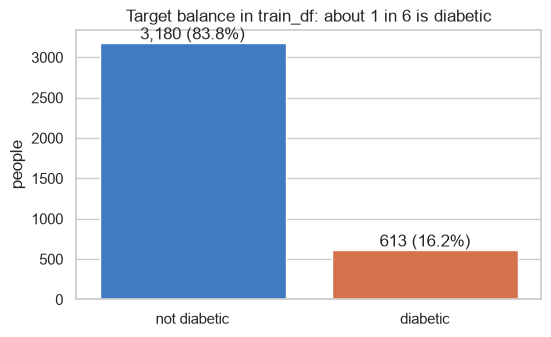

Accuracy of always predicting 'not diabetic': 83.8%


In [20]:
counts = eda_df["status"].value_counts().reindex(STATUS_COLORS.keys())

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=STATUS_COLORS, legend=False, ax=ax)
for i, n in enumerate(counts.values):
    ax.text(i, n, f"{n:,} ({n / counts.sum():.1%})", ha="center", va="bottom")
ax.set(title="Target balance in train_df: about 1 in 6 is diabetic", xlabel="", ylabel="people")
plt.show()

print(f"Accuracy of always predicting 'not diabetic': {1 - eda_df[TARGET].mean():.1%}")

### 3.2 Missing values per feature

Shows the share of missing values for each feature, **separately for diabetics and non-diabetics**. If a feature is missing more often in one group, the fact that it is missing carries information, and a missing-value flag could capture it.

The table is sorted by overall missing share; `gap` is diabetic minus non-diabetic, in percentage points.

`p_value` asks whether a gap could be luck. It comes from **Fisher's exact test** on a 2×2 table (missing or present × diabetic or not): the chance of a split at least this lopsided if missingness had nothing to do with diabetes. With 15 features tested, one small p-value is expected by luck alone, so the cut-off is divided by the number of tests (**Bonferroni**: 0.05 / 15 ≈ 0.003).

Bonferroni cut-off: 0.05 / 15 = 0.0033; features below it: 0


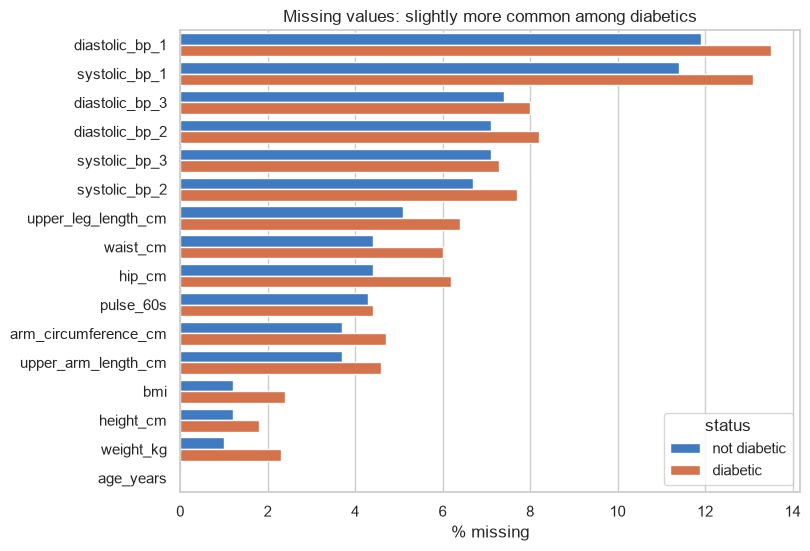

,overall,not diabetic,diabetic,gap,p_value
diastolic_bp_1,12.2,11.9,13.5,1.6,0.280
systolic_bp_1,11.6,11.4,13.1,1.7,0.242
diastolic_bp_3,7.5,7.4,8.0,0.6,0.615
diastolic_bp_2,7.3,7.1,8.2,1.1,0.351
systolic_bp_3,7.2,7.1,7.3,0.2,0.864
systolic_bp_2,6.9,6.7,7.7,1.0,0.383
upper_leg_length_cm,5.3,5.1,6.4,1.3,0.199
waist_cm,4.7,4.4,6.0,1.6,0.095
hip_cm,4.7,4.4,6.2,1.8,0.062
pulse_60s,4.4,4.3,4.4,0.1,0.914


In [21]:
missing = pd.DataFrame({
    "overall": eda_df[NUMERIC_FEATURES].isna().mean(),
    "not diabetic": eda_df.loc[eda_df[TARGET] == 0, NUMERIC_FEATURES].isna().mean(),
    "diabetic": eda_df.loc[eda_df[TARGET] == 1, NUMERIC_FEATURES].isna().mean(),
}).mul(100).round(1).sort_values("overall", ascending=False)
missing["gap"] = missing["diabetic"] - missing["not diabetic"]


def missing_p_value(col):
    is_missing = eda_df[col].isna()
    if not is_missing.any():
        return float("nan")
    return fisher_exact(pd.crosstab(is_missing, eda_df[TARGET]))[1]


missing["p_value"] = [round(missing_p_value(col), 3) for col in missing.index]
tested = missing["p_value"].notna().sum()
print(f"Bonferroni cut-off: 0.05 / {tested} = {0.05 / tested:.4f}; features below it: {(missing['p_value'] < 0.05 / tested).sum()}")

long = missing[list(STATUS_COLORS)].reset_index(names="feature").melt(
    id_vars="feature", var_name="status", value_name="missing_pct"
)
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=long, y="feature", x="missing_pct", hue="status", palette=STATUS_COLORS, ax=ax)
ax.set(title="Missing values: slightly more common among diabetics", xlabel="% missing", ylabel="")
plt.show()

missing

### 3.3 Distributions

One histogram per numeric feature, all in one grid. Things to look for:
- **skew:** a long tail on one side (e.g. weight, BMI)
- **spikes:** a pile-up at one value (e.g. age at 80, which means "80 or older")
- **stray values:** isolated bars far from the rest, which 3.4 examines

The comb-like gaps in the age and blood pressure plots are not a data problem: age is a whole number and BP is recorded in steps of 2 mmHg, so some histogram bins catch more possible values than others.

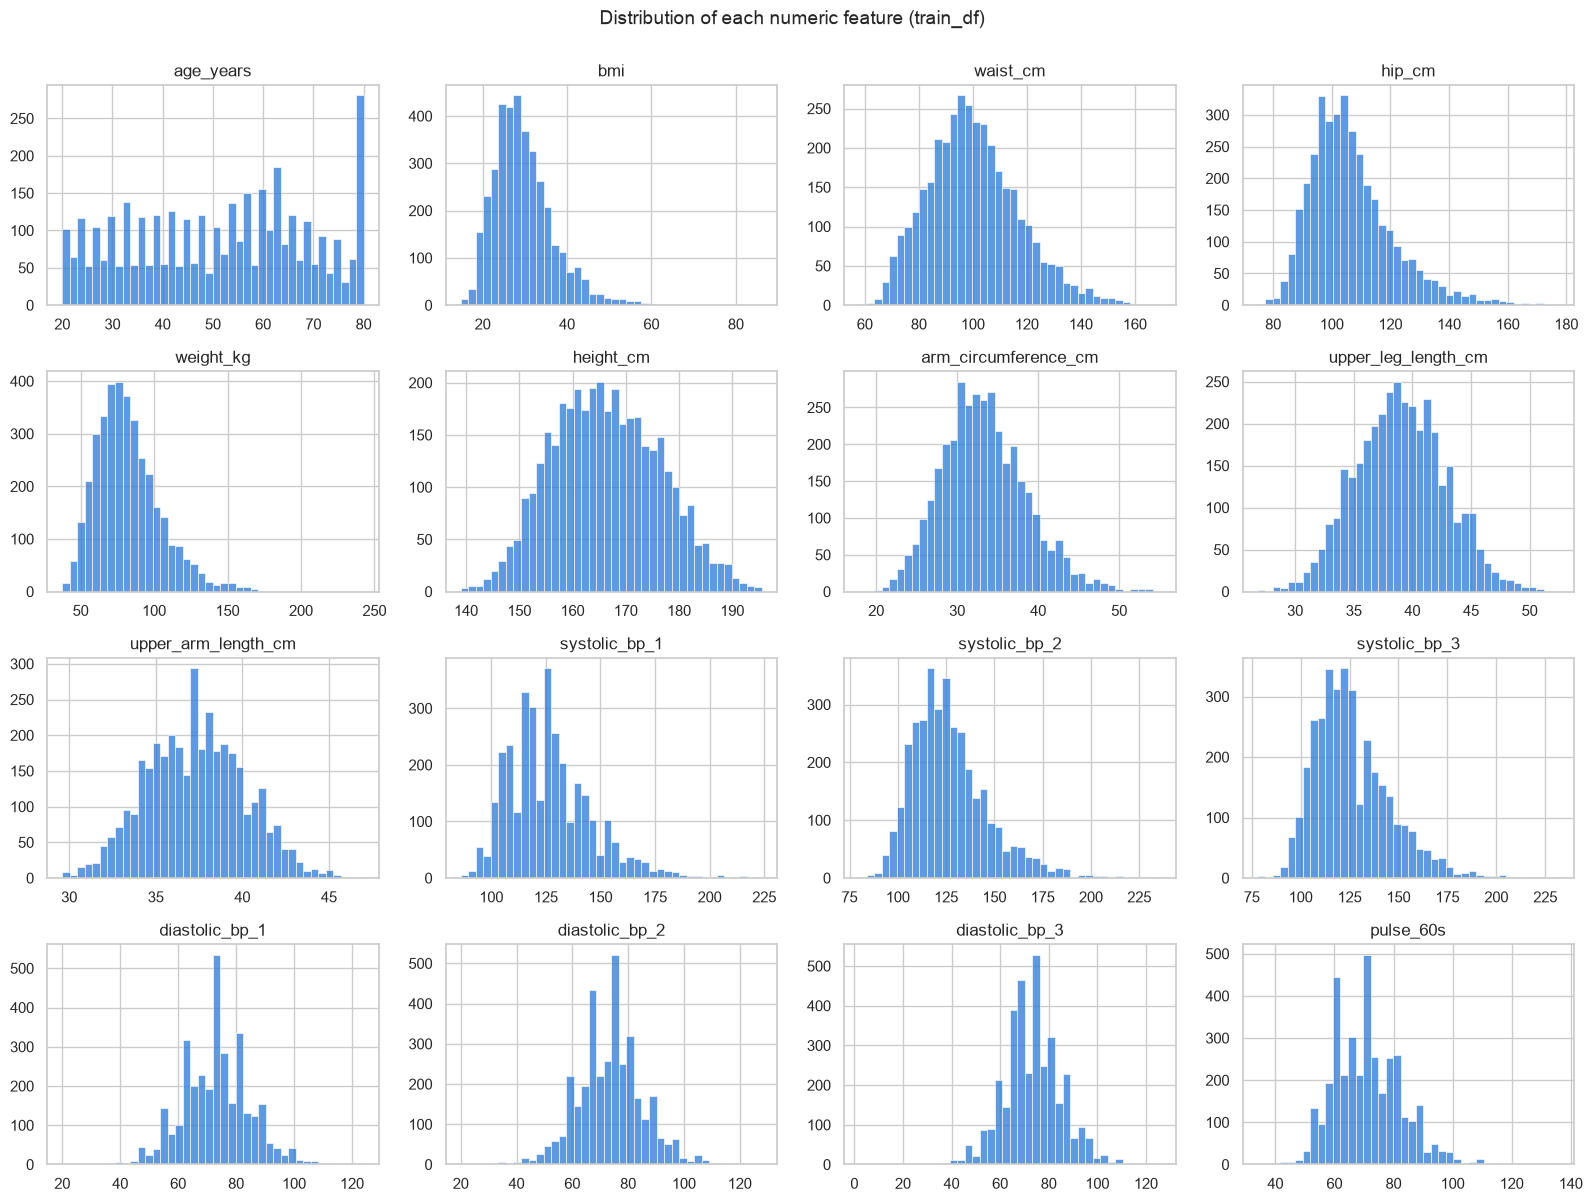

In [22]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.flat, NUMERIC_FEATURES):
    sns.histplot(eda_df[col].dropna(), bins=40, color=SINGLE_COLOR, ax=ax)
    ax.set(title=col, xlabel="", ylabel="")
fig.suptitle("Distribution of each numeric feature (train_df)", y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

### 3.4 Outliers and impossible values

Two views of the extremes:
1. **Percentile table:** the minimum, 0.5th percentile, median, 99.5th percentile and maximum of each feature. A minimum or maximum far beyond the 0.5th or 99.5th percentile is an isolated extreme.
2. **Low diastolic readings:** NHANES zeros are already missing (2.2), but nearby very low readings can also be measurement failures. The count shows how many readings fall below 40 mmHg, a level that is very rare in a seated, resting adult.

In [23]:
extremes = eda_df[NUMERIC_FEATURES].quantile([0, 0.005, 0.5, 0.995, 1]).T
extremes.columns = ["min", "p0.5", "median", "p99.5", "max"]
display(extremes.round(1))

low = eda_df[DIASTOLIC_COLS] < LOW_DIASTOLIC
print(f"Diastolic readings below {LOW_DIASTOLIC}: {low.sum().to_dict()}")
print(f"People with at least one: {low.any(axis=1).sum()}")
eda_df.loc[low.any(axis=1), ["person_id"] + SYSTOLIC_COLS + DIASTOLIC_COLS].head(10)

,min,p0.5,median,p99.5,max
age_years,20.0,20.0,52.0,80.0,80.0
bmi,14.8,17.2,28.5,56.7,86.2
waist_cm,57.9,67.2,98.7,151.9,169.5
hip_cm,74.7,81.6,104.1,158.5,177.5
weight_kg,37.5,43.4,78.8,162.0,242.6
height_cm,139.0,143.8,165.7,190.9,195.6
arm_circumference_cm,17.9,22.2,33.0,49.5,55.1
upper_leg_length_cm,26.8,30.0,39.0,49.0,52.5
upper_arm_length_cm,29.6,30.6,37.2,45.0,47.0
systolic_bp_1,86.0,92.0,124.0,194.0,224.0


Diastolic readings below 40: {'diastolic_bp_1': 10, 'diastolic_bp_2': 16, 'diastolic_bp_3': 14}
People with at least one: 25


,person_id,systolic_bp_1,systolic_bp_2,systolic_bp_3,diastolic_bp_1,diastolic_bp_2,diastolic_bp_3
72,93832,130.0,138.0,132.0,52.0,32.0,30.0
761,95128,106.0,112.0,108.0,38.0,36.0,42.0
3605,100721,118.0,114.0,112.0,NaN,36.0,34.0
3566,100639,154.0,148.0,142.0,38.0,34.0,36.0
1580,96704,140.0,146.0,NaN,32.0,38.0,NaN
55,93800,154.0,156.0,148.0,NaN,NaN,12.0
3748,101010,108.0,104.0,102.0,46.0,44.0,38.0
3256,99997,118.0,110.0,110.0,20.0,20.0,58.0
3083,99643,120.0,132.0,128.0,46.0,44.0,38.0
2410,98347,134.0,138.0,136.0,36.0,44.0,34.0


### 3.5 Each feature vs the target

One box plot per numeric feature, split by diabetes status. The box covers the middle 50% of people and the line inside is the median. **The further apart the two boxes, the more that feature separates the groups on its own.**

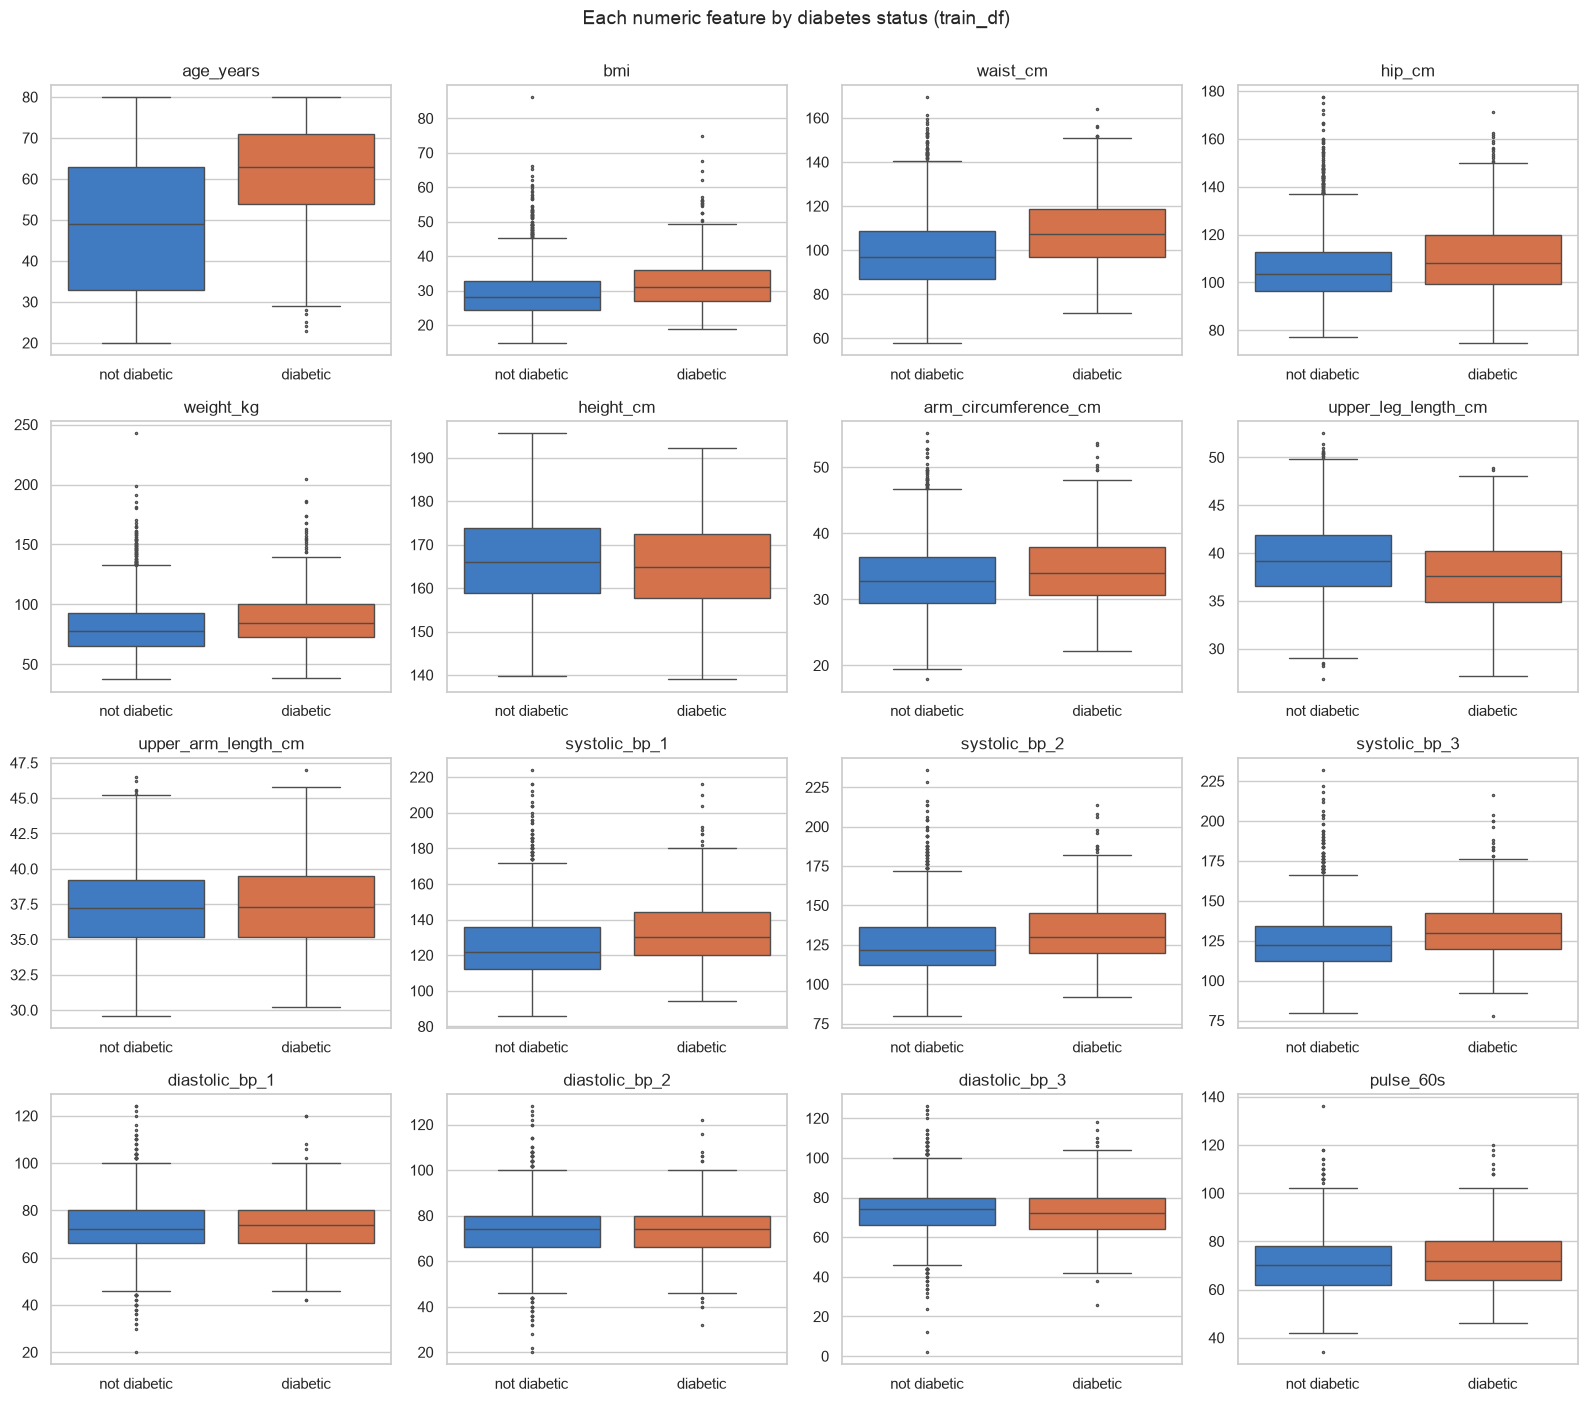

In [24]:
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
for ax, col in zip(axes.flat, NUMERIC_FEATURES):
    sns.boxplot(
        data=eda_df, x="status", y=col, hue="status", order=list(STATUS_COLORS),
        palette=STATUS_COLORS, fliersize=1.5, legend=False, ax=ax,
    )
    ax.set(title=col, xlabel="", ylabel="")
fig.suptitle("Each numeric feature by diabetes status (train_df)", y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

### 3.6 Diabetic rate by sex and age group

Box plots don't suit `gender`, and age is easier to read in bands. This cell shows the **share of people who are diabetic** in each sex and in each age group, with the group size printed on each bar.

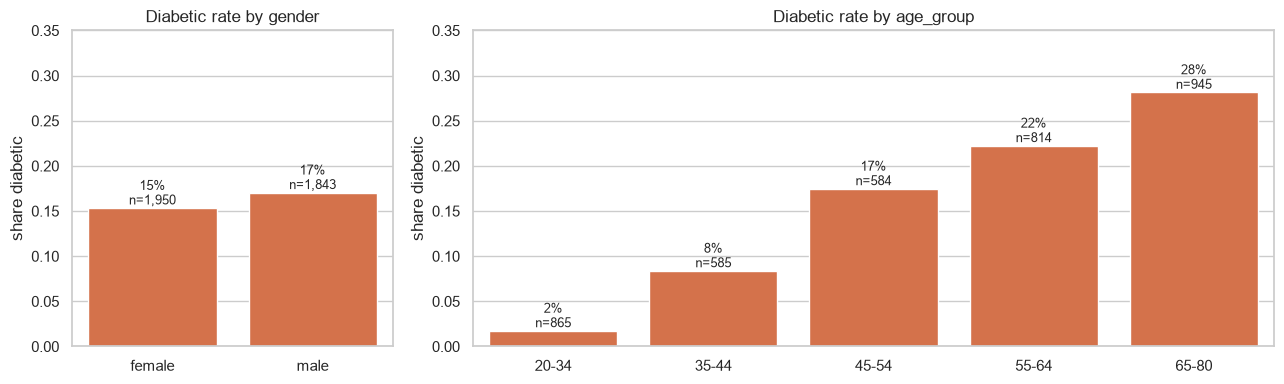

In [25]:
AGE_BANDS = [19, 34, 44, 54, 64, 80]
AGE_LABELS = ["20-34", "35-44", "45-54", "55-64", "65-80"]
by_age = eda_df.assign(age_group=pd.cut(eda_df["age_years"], bins=AGE_BANDS, labels=AGE_LABELS))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 2.5]})
for ax, (col, df) in zip(axes, [("gender", eda_df), ("age_group", by_age)]):
    rate = df.groupby(col, observed=True)[TARGET].agg(["mean", "size"])
    sns.barplot(x=rate.index.astype(str), y=rate["mean"], color=STATUS_COLORS["diabetic"], ax=ax)
    for i, (r, n) in enumerate(zip(rate["mean"], rate["size"])):
        ax.text(i, r, f"{r:.0%}\nn={n:,}", ha="center", va="bottom", fontsize=9)
    ax.set(title=f"Diabetic rate by {col}", xlabel="", ylabel="share diabetic", ylim=(0, 0.35))
plt.tight_layout()
plt.show()

### 3.7 Single-feature ROC-AUC ranking

For each feature **on its own**: pick a random diabetic and a random non-diabetic. How often does this feature give the diabetic the higher value?
- **0.5** = a coin flip, no signal
- **above 0.5** = higher values mean higher risk
- **below 0.5** = **lower** values mean higher risk (still useful; the signal is just reversed)

`strength` = distance from 0.5, which ranks features regardless of direction. Rows with a missing value are skipped for that feature only. For `gender`, "higher" means female.

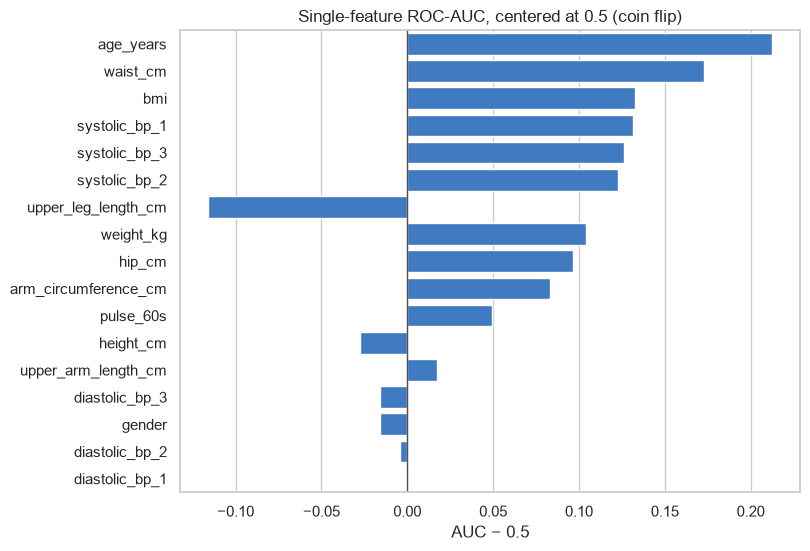

,auc,strength,direction
age_years,0.712,0.212,higher = more risk
waist_cm,0.673,0.173,higher = more risk
bmi,0.632,0.132,higher = more risk
systolic_bp_1,0.631,0.131,higher = more risk
systolic_bp_3,0.626,0.126,higher = more risk
systolic_bp_2,0.623,0.123,higher = more risk
upper_leg_length_cm,0.384,0.116,lower = more risk
weight_kg,0.604,0.104,higher = more risk
hip_cm,0.596,0.096,higher = more risk
arm_circumference_cm,0.583,0.083,higher = more risk


In [26]:
def single_feature_auc(values, target):
    has_value = values.notna()
    return roc_auc_score(target[has_value], values[has_value])


auc = pd.Series(
    {col: single_feature_auc(eda_df[col], eda_df[TARGET]) for col in NUMERIC_FEATURES}
    | {"gender": single_feature_auc((eda_df["gender"] == "female").astype(int), eda_df[TARGET])}
)
ranking = pd.DataFrame({"auc": auc, "strength": (auc - 0.5).abs()}).sort_values("strength", ascending=False)
ranking["direction"] = np.where(ranking["auc"] >= 0.5, "higher = more risk", "lower = more risk")

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=ranking["auc"] - 0.5, y=ranking.index, color=SINGLE_COLOR, ax=ax)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set(title="Single-feature ROC-AUC, centered at 0.5 (coin flip)", xlabel="AUC − 0.5", ylabel="")
plt.show()

ranking.round(3)

### 3.8 Correlations and redundant features

A heatmap of the correlation between every pair of numeric features: **red** = they rise together, **blue** = one rises as the other falls, **gray** = unrelated. The table lists the pairs above 0.8, which carry largely the same information.

Redundant features don't hurt tree models much, but they make logistic regression weights unstable and hard to interpret.

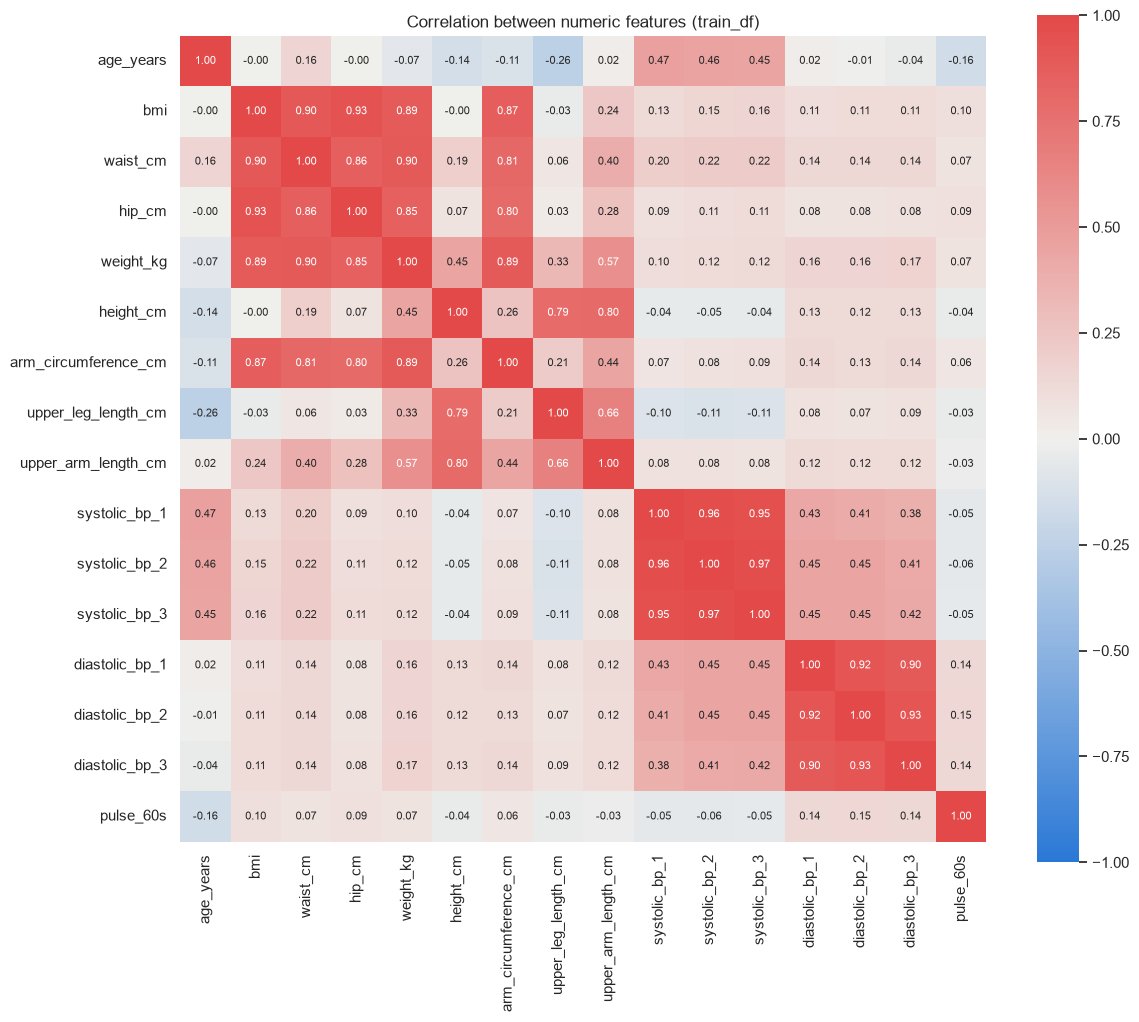

correlation
systolic_bp_2  systolic_bp_3                0.97
systolic_bp_1  systolic_bp_2                0.96
               systolic_bp_3                0.95
bmi            hip_cm                       0.93
diastolic_bp_2 diastolic_bp_3               0.93
diastolic_bp_1 diastolic_bp_2               0.92
bmi            waist_cm                     0.90
diastolic_bp_1 diastolic_bp_3               0.90
waist_cm       weight_kg                    0.90
weight_kg      arm_circumference_cm         0.89
bmi            weight_kg                    0.89
               arm_circumference_cm         0.87
waist_cm       hip_cm                       0.86
hip_cm         weight_kg                    0.85
waist_cm       arm_circumference_cm         0.81
hip_cm         arm_circumference_cm         0.80
height_cm      upper_arm_length_cm          0.80

In [27]:
corr = eda_df[NUMERIC_FEATURES].corr()

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap=CORRELATION_CMAP, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 8}, square=True, ax=ax)
ax.set_title("Correlation between numeric features (train_df)")
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
upper[upper.abs() > 0.8].sort_values(ascending=False).round(2).rename("correlation").to_frame()

### 3.9 Effect of blood pressure medication

`taking_bp_meds` is EDA-only. This cell asks two questions about it, using each person's **average systolic** across their available readings:
1. **Left:** how much more common is diabetes among people taking BP medicine?
2. **Right:** among people **not** on medicine, diabetics have higher systolic BP. Does that gap survive among people **on** medicine, whose readings are lowered by the pills?

The table gives the median systolic for each of the four groups.

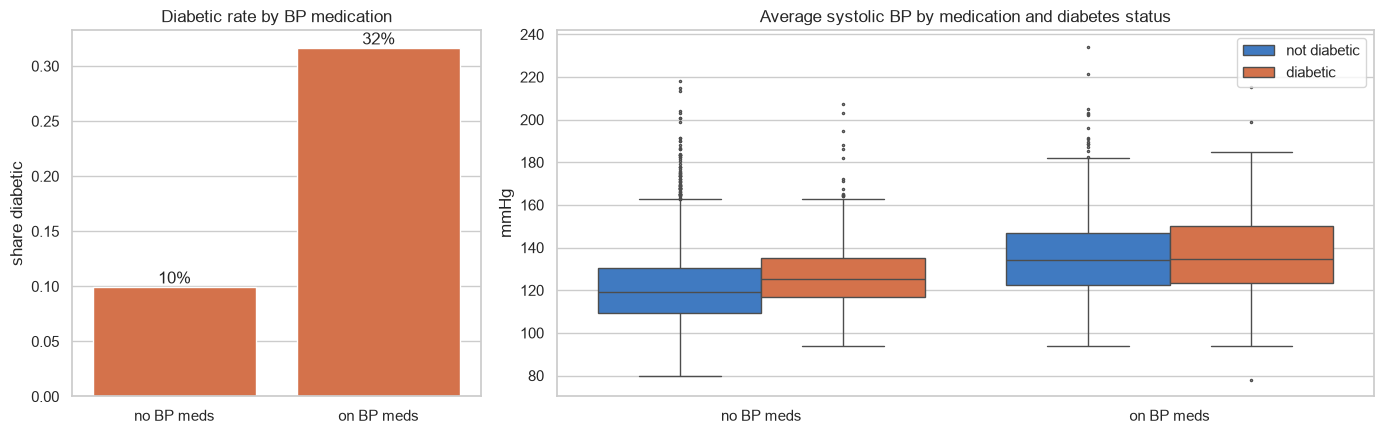

status,diabetic,not diabetic
on_bp_meds,,
no BP meds,125.3,119.3
on BP meds,134.7,134.0


In [28]:
bp_view = eda_df.assign(
    mean_systolic=eda_df[SYSTOLIC_COLS].mean(axis=1),
    on_bp_meds=eda_df["taking_bp_meds"].map({0: "no BP meds", 1: "on BP meds"}),
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2]})
rate = bp_view.groupby("on_bp_meds")[TARGET].mean()
sns.barplot(x=rate.index, y=rate.values, color=STATUS_COLORS["diabetic"], ax=axes[0])
for i, r in enumerate(rate.values):
    axes[0].text(i, r, f"{r:.0%}", ha="center", va="bottom")
axes[0].set(title="Diabetic rate by BP medication", xlabel="", ylabel="share diabetic")

sns.boxplot(
    data=bp_view, x="on_bp_meds", y="mean_systolic", order=["no BP meds", "on BP meds"],
    hue="status", hue_order=list(STATUS_COLORS),
    palette=STATUS_COLORS, fliersize=1.5, ax=axes[1],
)
axes[1].set(title="Average systolic BP by medication and diabetes status", xlabel="", ylabel="mmHg")
axes[1].legend(title="")
plt.tight_layout()
plt.show()

bp_view.pivot_table(index="on_bp_meds", columns="status", values="mean_systolic", aggfunc="median").round(1)

### 3.10 Findings → Step 4 actions

What EDA found on `train_df` (`random_state=42`) and what each finding means for the next steps.

| # | Finding | Evidence | Action |
|---|---|---|---|
| 1 | **Imbalanced target:** 16.2% diabetic | 3.1: always guessing "not diabetic" scores 83.8% accuracy | Judge models by ROC-AUC, average precision and recall, not accuracy (Step 7); try `class_weight="balanced"` (6.2) |
| 2 | **Missing values are modest** (at most 12%, the first BP reading) and only **slightly more common among diabetics** | 3.2: e.g. weight 2.3% vs 1.0%, waist 6.0% vs 4.4%; smallest p-value 0.016 (weight), none below the Bonferroni cut-off of 0.003 | Median imputing, **no missing-value flags** (4.3); optionally test one "any body measure missing" flag (8.3) |
| 3 | **Very low diastolic readings** look like measurement failures | 3.4: 25 people have a diastolic below 40 | Treat diastolic < 40 as missing (4.1) |
| 4 | **Extreme but possible values:** BMI up to 86, weight up to 243 kg, systolic up to 236 | 3.4: a handful of people each | Keep them; check later whether clipping at the 0.5th / 99.5th percentile helps (8.3) |
| 5 | **Age is the strongest single feature**, then waist, BMI and systolic BP | 3.7: AUC 0.71, 0.67, 0.63, 0.63; diabetic rate climbs from 2% (20–34) to 28% (65–80) | Core features; keep all |
| 6 | **Shorter upper legs mean higher risk** | 3.7: AUC 0.38, the strongest *reversed* signal. Partly explained by age: older people have shorter upper legs (3.8: correlation −0.3) | Keep; build leg-to-height ratio (4.2); check it adds signal beyond age (8.3) |
| 7 | **Diastolic BP, height and sex carry almost no signal on their own** | 3.7: AUC 0.47–0.50 | Keep for now; test whether they help in combination (8.3) |
| 8 | **The three BP readings are near-duplicates** | 3.8: correlation 0.90–0.97 | Average them into `mean_systolic` and `mean_diastolic` (4.2) |
| 9 | **Body measures are one cluster:** BMI, weight, waist, hip, arm circumference | 3.8: correlation 0.80–0.93 | Fine for trees; for logistic regression, prefer ratios (waist-to-height) and check weight stability (4.2, 8.3) |
| 10 | **BP medication hides the BP–diabetes link** | 3.9: without meds, diabetics' median systolic is 6 mmHg higher; with meds, the gap almost disappears. 32% of people on BP meds are diabetic vs 10% without | Strong candidate signal: test flipping `taking_bp_meds` to a feature and the BP correction (8.4) |

### Step 3 summary

- EDA ran on `train_df` only and changed nothing in it.
- The findings table (3.10) turns each observation into an action for Step 4 or later.

**Next, Step 4 (feature preparation and engineering):** clean the low diastolic readings, build averaged BP and body-shape ratio features, then assemble the imputing, encoding and scaling `Pipeline`.

## Step 4 — Feature preparation and engineering

Turns the raw feature columns into model-ready numbers. The work comes in two kinds:

| Kind | Example | Learns from data? | Where it lives |
|---|---|---|---|
| **Fixed rules** (4.1–4.2) | "diastolic below 40 → missing", "waist ÷ height" | No: each row is handled on its own | A plain function |
| **Fitted steps** 🔁 (4.3–4.5) | "fill missing BMI with the **median**" | Yes: the median comes from the rows it sees | A scikit-learn `Pipeline` |

Fitted steps are where **data leakage** sneaks in: a median computed on all rows would carry information from the validation fold or the test set into training. Inside a `Pipeline` they are refit on the training part of every CV fold.

In 4.6 the fixed-rule functions become the first stages of that pipeline, so **one object turns raw columns into model-ready numbers**, the same way for training, every CV fold and the test set.

The rules were decided on `train_df` in 3.10, and this step still only touches `train_df`.

### 4.1 Impossible values

`fix_impossible_values` turns every diastolic reading below `LOW_DIASTOLIC` (40 mmHg) into missing, **one reading at a time**: a person with readings 20, 20, 58 keeps the 58. It returns a new table and leaves the one it was given untouched.

The check below counts, for each reading, the low values found and the missing values before and after. *Missing after* must equal *missing before* plus *below 40*.

In [29]:
def fix_impossible_values(df):
    """Returns a copy of df with diastolic readings below LOW_DIASTOLIC set to missing."""
    df = df.copy()
    df[DIASTOLIC_COLS] = df[DIASTOLIC_COLS].mask(df[DIASTOLIC_COLS] < LOW_DIASTOLIC)
    return df

fixed = fix_impossible_values(train_df)
fix_check = pd.DataFrame({
    f"below {LOW_DIASTOLIC}": (train_df[DIASTOLIC_COLS] < LOW_DIASTOLIC).sum(),
    "missing before": train_df[DIASTOLIC_COLS].isna().sum(),
    "missing after": fixed[DIASTOLIC_COLS].isna().sum(),
})
assert (fix_check["missing after"] == fix_check["missing before"] + fix_check[f"below {LOW_DIASTOLIC}"]).all()
assert not (fixed[DIASTOLIC_COLS] < LOW_DIASTOLIC).any().any()
print(fixed.shape)
fix_check

(3793, 20)


,below 40,missing before,missing after
diastolic_bp_1,10,462,472
diastolic_bp_2,16,276,292
diastolic_bp_3,14,284,298


### 4.2 Derived features

`add_derived_features` builds five new columns:
- **`mean_systolic`, `mean_diastolic`:** the average of each person's own readings. Missing readings are skipped, so anyone with at least one good reading gets a value; the result is missing only if all three are. The six separate readings are then **dropped**: they are near-duplicates (3.8) and the mean is less noisy.
- **`waist_to_height`, `waist_to_hip`:** body *shape* rather than size. Belly fat is the type linked to insulin resistance, and a ratio compares it with the person's own frame.
- **`leg_to_height`:** upper leg length relative to height, testing the reversed signal from 3.7 without the effect of overall height.

A ratio is missing if either of its parts is missing.

`MODEL_FEATURES` is the new feature list: the original features without the BP readings, plus the derived ones.

In [30]:
DERIVED_FROM = {
    "mean_systolic": SYSTOLIC_COLS,
    "mean_diastolic": DIASTOLIC_COLS,
    "waist_to_height": ["waist_cm", "height_cm"],
    "waist_to_hip": ["waist_cm", "hip_cm"],
    "leg_to_height": ["upper_leg_length_cm", "height_cm"],
}
DERIVED_FEATURES = list(DERIVED_FROM)
BP_READING_COLS = SYSTOLIC_COLS + DIASTOLIC_COLS


def add_derived_features(df):
    """Returns a copy of df with averaged BP and body-shape ratios; the separate BP readings are dropped."""
    df = df.copy()
    df["mean_systolic"] = df[SYSTOLIC_COLS].mean(axis=1)
    df["mean_diastolic"] = df[DIASTOLIC_COLS].mean(axis=1)
    df["waist_to_height"] = df["waist_cm"] / df["height_cm"]
    df["waist_to_hip"] = df["waist_cm"] / df["hip_cm"]
    df["leg_to_height"] = df["upper_leg_length_cm"] / df["height_cm"]
    return df.drop(columns=BP_READING_COLS)


MODEL_FEATURES = [f for f in FEATURES if f not in BP_READING_COLS] + DERIVED_FEATURES
print(f"{len(MODEL_FEATURES)} model features: {MODEL_FEATURES}")

16 model features: ['age_years', 'gender', 'bmi', 'waist_cm', 'hip_cm', 'weight_kg', 'height_cm', 'arm_circumference_cm', 'upper_leg_length_cm', 'upper_arm_length_cm', 'pulse_60s', 'mean_systolic', 'mean_diastolic', 'waist_to_height', 'waist_to_hip', 'leg_to_height']


### 4.2 check: do the new features work?

Applies both fixed rules to `train_df` and shows:
1. **A few people with low diastolic readings** (from 3.4) next to their new `mean_diastolic`: the bad readings are skipped, and someone with no good reading is left missing for 4.3 to fill.
2. **Each derived feature's missing count and single-feature AUC** (as in 3.7), next to the strongest column it was built from. A derived feature earns its place if it is stronger than its parts, or if it carries the same signal in fewer columns with fewer gaps.

In [31]:
prepared_train = add_derived_features(fix_impossible_values(train_df))

has_low_reading = (train_df[DIASTOLIC_COLS] < LOW_DIASTOLIC).any(axis=1)
print(has_low_reading.iloc[10:20])

display(train_df.loc[has_low_reading, ["person_id"] + DIASTOLIC_COLS].head(5).join(prepared_train["mean_diastolic"]))

derived_auc = pd.Series({f: single_feature_auc(prepared_train[f], prepared_train[TARGET]) for f in DERIVED_FEATURES})
strongest_source = {f: ranking.loc[cols, "strength"].idxmax() for f, cols in DERIVED_FROM.items()}
pd.DataFrame({
    "missing": prepared_train[DERIVED_FEATURES].isna().sum(),
    "auc": derived_auc,
    "strength": (derived_auc - 0.5).abs(),
    "strongest source": strongest_source,
    "source missing": {f: train_df[src].isna().sum() for f, src in strongest_source.items()},
    "source strength": {f: ranking.loc[src, "strength"] for f, src in strongest_source.items()},
}).round(3)

2130    False
3286    False
4351    False
694     False
1285    False
2911    False
1705    False
1086    False
1864    False
4623    False
dtype: bool


,person_id,diastolic_bp_1,diastolic_bp_2,diastolic_bp_3,mean_diastolic
72,93832,52.0,32.0,30.0,52.0
761,95128,38.0,36.0,42.0,42.0
3605,100721,NaN,36.0,34.0,NaN
3566,100639,38.0,34.0,36.0,NaN
1580,96704,32.0,38.0,NaN,NaN


,missing,auc,strength,strongest source,source missing,source strength
mean_systolic,180,0.627,0.127,systolic_bp_1,441,0.131
mean_diastolic,198,0.491,0.009,diastolic_bp_3,284,0.016
waist_to_height,183,0.685,0.185,waist_cm,178,0.173
waist_to_hip,189,0.688,0.188,waist_cm,178,0.173
leg_to_height,203,0.345,0.155,upper_leg_length_cm,200,0.116


### 4.3 🔁 Imputing missing values

Every model needs a value in every cell. `SimpleImputer(strategy="median")` works in two moves:
- **`fit`** learns one median per column from the rows it is given.
- **`transform`** fills each gap with that column's learned median.

The median, not the mean, because the body measures are skewed (3.3): a few very heavy people would pull a mean upward. No missing-value flags are added (3.2).

This cell fits an imputer on all of `prepared_train` **just to look** at what it learns. In the pipeline (4.6), the imputer is refit on the training part of every CV fold, so its medians never come from validation rows.

In [32]:
NUMERIC_MODEL_FEATURES = [f for f in MODEL_FEATURES if f != "gender"]

imputer = SimpleImputer(strategy="median").fit(prepared_train[NUMERIC_MODEL_FEATURES])
pd.DataFrame({
    "missing": prepared_train[NUMERIC_MODEL_FEATURES].isna().sum(),
    "learned median": imputer.statistics_,
}).round(3)

,missing,learned median
age_years,0,52.000
bmi,54,28.500
waist_cm,178,98.700
hip_cm,179,104.100
weight_kg,47,78.800
height_cm,49,165.700
arm_circumference_cm,147,33.000
upper_leg_length_cm,200,39.000
upper_arm_length_cm,145,37.200
pulse_60s,165,70.000


### 4.4 🔁 Encoding `gender`

Models need numbers, not labels. `OneHotEncoder` gives each category its own 0/1 column; with `drop="if_binary"`, a two-value column like `gender` becomes a **single** column, `gender_male` (1 = male, 0 = female). Two columns would just repeat each other.

`fit` learns the categories; `transform` turns labels into 0/1. The output shows each label next to its code.

In [33]:
encoder = OneHotEncoder(drop="if_binary", sparse_output=False).fit(prepared_train[["gender"]])
encoded = pd.DataFrame(encoder.transform(prepared_train[["gender"]]), columns=encoder.get_feature_names_out())
pd.crosstab(prepared_train["gender"].to_numpy(), encoded["gender_male"], rownames=["gender"])

gender_male,0.0,1.0
gender,,
female,1950,0
male,0,1843


### 4.5 🔁 Scaling

`StandardScaler` rescales each numeric column to **mean 0 and standard deviation 1**: `(value − mean) / std`. Afterwards "1" means "one standard deviation above average" in every column, whether it was measured in years, cm or mmHg.

- **Logistic regression needs it:** its penalty on large weights (regularization) is only fair when features share a scale, and it trains more reliably.
- **Tree models don't care**, but scaling doesn't hurt them.

`fit` learns each column's mean and std; `transform` applies them. The table compares a few columns before and after, after filling gaps as in 4.3.

In [34]:
filled = pd.DataFrame(imputer.transform(prepared_train[NUMERIC_MODEL_FEATURES]), columns=NUMERIC_MODEL_FEATURES)
scaler = StandardScaler().fit(filled)
scaled = pd.DataFrame(scaler.transform(filled), columns=NUMERIC_MODEL_FEATURES)

examples = ["age_years", "waist_cm", "mean_systolic", "waist_to_hip"]
pd.concat({"before": filled[examples].agg(["mean", "std"]), "after": scaled[examples].agg(["mean", "std"])}).round(3)

age_years  waist_cm  mean_systolic  waist_to_hip
before mean     51.040   100.121        126.740         0.938
       std      17.521    16.445         19.069         0.079
after  mean     -0.000     0.000          0.000        -0.000
       std       1.000     1.000          1.000         1.000

### 4.6 Assemble the preprocessing `Pipeline`

One object, `preprocess`, chains every Step 4 operation:
1. `fix_impossible_values` (4.1) and `add_derived_features` (4.2), wrapped in `FunctionTransformer` so they act as pipeline stages. They learn nothing.
2. A `ColumnTransformer` that sends each group of columns down its own path:
   - **numeric** → median imputing (4.3) → scaling (4.5)
   - **`gender`** → one-hot encoding (4.4)

It takes the **raw feature columns** (`FEATURES`) and returns model-ready numbers. Calling `fit` on it fits every 🔁 stage on the rows given, in order. In Step 5 a model is added as the last stage, and cross-validation refits the whole thing on each fold's training part.

The diagram below is clickable: expand a box to see its settings.

In [35]:
preprocess = Pipeline([
    ("fix", FunctionTransformer(fix_impossible_values)),
    ("derive", FunctionTransformer(add_derived_features)),
    ("columns", ColumnTransformer(
        [
            ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC_MODEL_FEATURES),
            ("gender", OneHotEncoder(drop="if_binary", sparse_output=False), ["gender"]),
        ],
        verbose_feature_names_out=False,
    )),
]).set_output(transform="pandas")

preprocess

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('fix', ...), ('derive', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function fix...t 0x11b004f60>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of 

### 4.6 check: the pipeline output

Fits `preprocess` on `train_df` and checks the result:
- one row per person and one column per model feature (gender becomes `gender_male`)
- **no missing values left**
- numeric columns have mean 0 and standard deviation 1; `gender_male` stays 0/1

`X_train` (features) and `y_train` (target) are the names Steps 5–8 use.

In [36]:
X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_ready = preprocess.fit_transform(X_train)

assert X_ready.shape == (len(X_train), len(MODEL_FEATURES)), X_ready.shape
assert not X_ready.isna().any().any(), "missing values left"
assert set(X_ready["gender_male"].unique()) == {0, 1}
print(f"X_ready: {X_ready.shape[0]:,} people x {X_ready.shape[1]} columns, no missing values")

X_ready.agg(["mean", "std", "min", "max"]).T.round(2)

X_ready: 3,793 people x 16 columns, no missing values


,mean,std,min,max
age_years,-0.00,1.0,-1.77,1.65
bmi,-0.00,1.0,-2.06,7.85
waist_cm,0.00,1.0,-2.57,4.22
hip_cm,0.00,1.0,-2.28,5.07
weight_kg,-0.00,1.0,-2.00,7.17
height_cm,0.00,1.0,-2.72,2.92
arm_circumference_cm,-0.00,1.0,-3.00,4.23
upper_leg_length_cm,-0.00,1.0,-3.29,3.63
upper_arm_length_cm,0.00,1.0,-2.76,3.49
pulse_60s,0.00,1.0,-3.34,5.83


### Step 4 summary

- **Fixed rules:** diastolic readings below 40 are missing (4.1); the six BP readings became `mean_systolic` and `mean_diastolic`, and three body-shape ratios were added (4.2). The ratios beat their parts: waist-to-hip is now the strongest feature after age.
- **Fitted steps** 🔁: median imputing (4.3), one-hot `gender` (4.4), scaling (4.5).
- **`preprocess`** (4.6) chains them all: raw `FEATURES` in, 16 model-ready columns out. Its 🔁 stages learn only from the rows it is fit on.

**Next, Step 5 (base model):** add a model as the last pipeline stage and score it with stratified 5-fold CV, starting with a dummy that always says "not diabetic", then logistic regression.

## Step 5 — Base model

The first real scores, and the bar every later model has to beat:
1. a **dummy** that ignores the features and always says "not diabetic" (the floor)
2. **logistic regression**, the simplest real model

Both are scored with **stratified 5-fold cross-validation** on `train_df`. `test_df` stays sealed.

### 5.1 Cross-validation setup

**Stratified 5-fold CV** cuts `train_df` into 5 parts with the same diabetic rate. Each part takes one turn as the **validation fold** while the pipeline is fit on the other 4:

```
Round 1:  [VALID] [train] [train] [train] [train]
Round 2:  [train] [VALID] [train] [train] [train]
  ...
Round 5:  [train] [train] [train] [train] [VALID]
```

That gives 5 scores per metric, reported as **mean** and **std** (how much the score moves with the split).

`cv_scores(model)` puts `preprocess` (Step 4) and the model in one pipeline and runs it through CV. `cross_validate` makes a **fresh copy** of the pipeline for every round, so the medians, means and model weights are learned from that round's 4 training parts only.

The metrics (`SCORING`):
| Metric | Question it answers | Coin-flip level |
|---|---|---|
| `accuracy` | Share of people labelled correctly | misleading here (3.1) |
| `roc_auc` | Does the model rank diabetics above non-diabetics? (3.7) | 0.5 |
| `average_precision` | Ranking quality, focused on the diabetic class | 0.162 (the diabetic rate) |
| `recall` | Share of diabetics caught | — |
| `precision` | Share of flagged people who are diabetic | — |

`cv_scores` also reports `train_roc_auc`: the ROC-AUC on the 4 parts each round was **fit** on. Far above the validation ROC-AUC means the model memorized its training rows (overfitting, 6.1).

The table below the code shows the 5 folds.

In [37]:
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

SCORING = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0),
}


def cv_scores(model):
    """Runs preprocess + model through stratified CV on the training set; returns the mean and std of each metric."""
    pipeline = Pipeline([("preprocess", preprocess), ("model", model)])
    results = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True)
    scores = pd.DataFrame({metric: results[f"test_{metric}"] for metric in SCORING})
    scores["train_roc_auc"] = results["train_roc_auc"]
    return scores.agg(["mean", "std"])


pd.DataFrame([
    {"fold": k + 1, "train rows": len(fit_rows), "validation rows": len(valid_rows),
     "validation diabetic rate": round(y_train.iloc[valid_rows].mean(), 3)}
    for k, (fit_rows, valid_rows) in enumerate(cv.split(X_train, y_train))
]).set_index("fold")

,train rows,validation rows,validation diabetic rate
fold,,,
1,3034,759,0.162
2,3034,759,0.162
3,3034,759,0.162
4,3035,758,0.161
5,3035,758,0.161


### 5.2 Dummy baseline

`DummyClassifier(strategy="prior")` ignores every feature. It gives everyone the same probability, the diabetic rate (16.2%), so it always predicts "not diabetic".

Expect high accuracy and nothing else: it catches no diabetics (recall 0) and cannot rank anyone (ROC-AUC 0.5). **Any real model must clearly beat it on ROC-AUC, average precision and recall.**

In [38]:
dummy_scores = cv_scores(DummyClassifier(strategy="prior"))
dummy_scores.round(3)

,accuracy,roc_auc,average_precision,recall,precision,train_roc_auc
mean,0.838,0.5,0.162,0.0,0.0,0.5
std,0.001,0.0,0.001,0.0,0.0,0.0


### 5.3 Logistic regression baseline

Logistic regression computes a **weighted sum** of the 16 features, then squashes it into a **probability** between 0 and 1. The weights (coefficients) are what it learns. It predicts "diabetic" when the probability is **0.5 or more**.

Default settings, on purpose: this is the baseline. `max_iter=1000` only gives the solver enough steps to finish.

In [39]:
logreg_scores = cv_scores(LogisticRegression(max_iter=1000))
logreg_scores.round(3)

,accuracy,roc_auc,average_precision,recall,precision,train_roc_auc
mean,0.840,0.786,0.385,0.121,0.523,0.793
std,0.004,0.018,0.024,0.015,0.056,0.005


### 5.4 Comparison

The mean CV score of each model, side by side, with the best single feature (age, from 3.7) for reference on ROC-AUC.

In [40]:
comparison = pd.DataFrame({
    "dummy": dummy_scores.loc["mean"],
    "logistic regression": logreg_scores.loc["mean"],
}).T
comparison["roc_auc vs age alone"] = comparison["roc_auc"] - ranking.loc["age_years", "auc"]
comparison.round(3)

,accuracy,roc_auc,average_precision,recall,precision,train_roc_auc,roc_auc vs age alone
dummy,0.838,0.500,0.162,0.000,0.000,0.500,-0.212
logistic regression,0.840,0.786,0.385,0.121,0.523,0.793,0.074


### 5.5 Why is recall so low?

ROC-AUC says logistic regression **ranks** people well, yet recall says it catches few diabetics. The gap is the **0.5 cut-off**.

`cross_val_predict` gives every person in `train_df` a probability from the round in which they were in the validation fold, so no one is scored by a model that saw them. The histogram shows those probabilities for each group, with the 0.5 cut-off as a dashed line; the table counts how many people of each group land above it.

Only people to the right of the line are flagged. Because just 16% of people are diabetic, the model is rarely confident enough to cross 0.5. Moving the cut-off is the job of 8.2, and `class_weight="balanced"` in 6.2 is another fix.

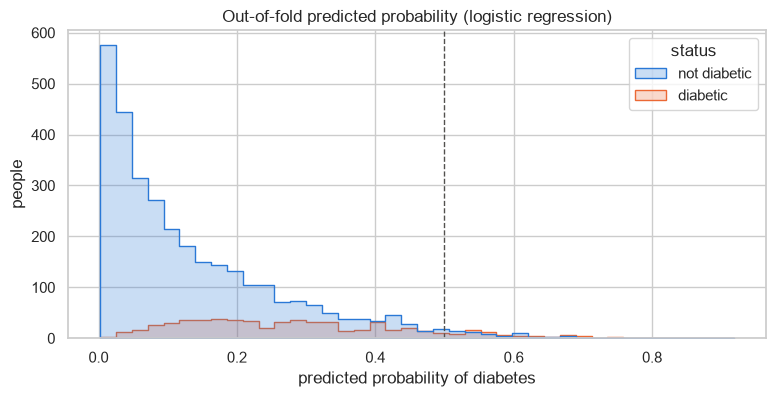

,people,median_probability,above_cutoff,share_above
status,,,,
diabetic,613,0.270,74,0.121
not diabetic,3180,0.093,69,0.022


In [41]:
DEFAULT_CUTOFF = 0.5

oof_proba = cross_val_predict(
    Pipeline([("preprocess", preprocess), ("model", LogisticRegression(max_iter=1000))]),
    X_train, y_train, cv=cv, method="predict_proba",
)[:, 1]
proba_df = pd.DataFrame({"probability": oof_proba, "status": y_train.map(STATUS_LABELS).to_numpy()})

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=proba_df, x="probability", hue="status", hue_order=list(STATUS_COLORS),
             palette=STATUS_COLORS, bins=40, element="step", ax=ax)
ax.axvline(DEFAULT_CUTOFF, color="#52514e", linestyle="--", linewidth=1)
ax.set(title="Out-of-fold predicted probability (logistic regression)", xlabel="predicted probability of diabetes", ylabel="people")
plt.show()

proba_df.groupby("status").agg(
    people=("probability", "size"),
    median_probability=("probability", "median"),
    above_cutoff=("probability", lambda p: (p >= DEFAULT_CUTOFF).sum()),
).assign(share_above=lambda t: t["above_cutoff"] / t["people"]).round(3)

### 5.6 What the logistic model learned

Fits the logistic pipeline once on all of `train_df` (for inspection only; the scores above come from CV) and plots its coefficients.

**How to read them:** features are scaled (4.5), so each coefficient is the change in the model's score (the *log-odds*) for **one standard deviation** more of that feature, holding the others fixed. Positive = more risk, negative = less. `exp(coefficient)` turns it into an odds multiplier: e.g. 0.86 for age means the odds of diabetes are about 2.4× higher per 17.5 years.

**Read the body measures with care.** BMI, weight, waist, hip and the ratios are strongly correlated (3.8), so the model splits the credit among them in ways that can look odd: a feature that is risky on its own can get a negative weight because a related feature already carries its signal. Trust the **group**, not each sign. 6.3 (regularization) and 8.3 (ablation) test this.

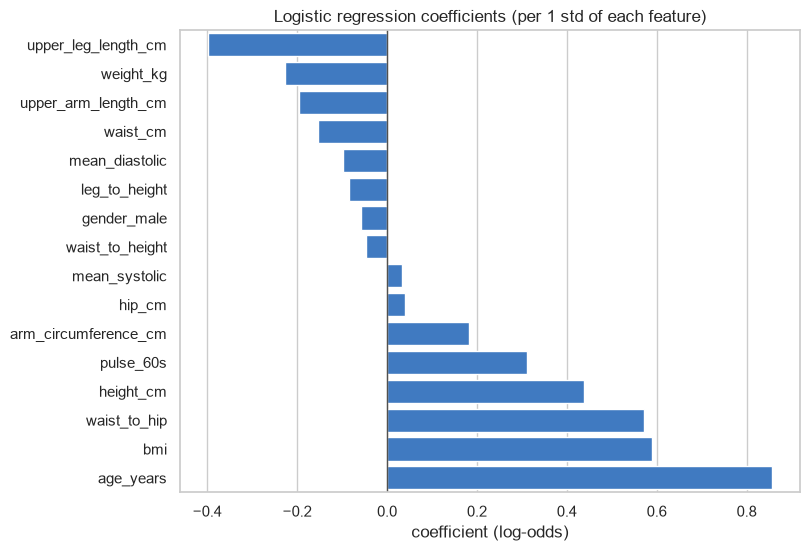

,coefficient,odds multiplier
age_years,0.856,2.355
bmi,0.590,1.803
waist_to_hip,0.573,1.773
height_cm,0.437,1.548
pulse_60s,0.311,1.364
arm_circumference_cm,0.182,1.200
hip_cm,0.040,1.041
mean_systolic,0.034,1.034
waist_to_height,-0.047,0.954
gender_male,-0.059,0.943


In [42]:
logreg = Pipeline([("preprocess", preprocess), ("model", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
coefficients = pd.Series(logreg[-1].coef_[0], index=logreg[-1].feature_names_in_).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=coefficients, y=coefficients.index, color=SINGLE_COLOR, ax=ax)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set(title="Logistic regression coefficients (per 1 std of each feature)", xlabel="coefficient (log-odds)", ylabel="")
plt.show()

pd.DataFrame({"coefficient": coefficients, "odds multiplier": np.exp(coefficients)}).sort_values("coefficient", ascending=False).round(3)

### Step 5 summary

- **Dummy:** 83.8% accuracy, ROC-AUC 0.5, recall 0. High accuracy with no skill.
- **Logistic regression:** ROC-AUC **0.786**, clearly above age alone (0.712), so combining features works. Average precision 0.385 vs 0.162 for the dummy.
- **The catch:** at the default 0.5 cut-off, recall is only about **12%**. The model ranks well but is rarely confident enough to say "diabetic" (5.5).
- **Coefficients:** age, BMI and waist-to-hip carry the most weight; correlated body measures share credit in ways that make single signs unreliable (5.6).

**Next, Step 6 (model fitting and tuning):** try random forest and gradient boosting, handle the class imbalance with `class_weight`, and tune settings with `GridSearchCV`, using `cv_scores` to compare.

## Step 6 — Model fitting and tuning

Does a more powerful model beat logistic regression's ROC-AUC of 0.786? Three candidates, all behind the same `preprocess` pipeline and scored with the same CV folds:

| Model | How it works |
|---|---|
| **Logistic regression** | A weighted sum of the features, squashed into a probability (5.3) |
| **Random forest** | Hundreds of decision trees (flowcharts of yes/no questions such as "age > 50?"), each grown on a random resample of the people; their probabilities are averaged |
| **Gradient boosting** | Trees grown one after another, each correcting the errors of the ones before |

Trees can learn thresholds and interactions ("high waist matters more after 50") that a weighted sum cannot. The price is flexibility: they can **memorize** the training rows.

Models are compared on **ROC-AUC**, which does not depend on the cut-off; the cut-off is chosen in 8.2.

### 6.1 Candidate models at default settings

Each candidate with scikit-learn's default settings (300 trees for the forest). `overfit gap` = training ROC-AUC minus validation ROC-AUC: near 0 means the model does as well on new people as on the ones it learned from; a large gap means it memorized.

In [43]:
N_TREES = 300

CANDIDATES = {
    "logistic regression": LogisticRegression(max_iter=1000),
    "random forest": RandomForestClassifier(n_estimators=N_TREES, random_state=RANDOM_STATE, n_jobs=-1),
    "gradient boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

default_scores = pd.DataFrame({name: cv_scores(model).loc["mean"] for name, model in CANDIDATES.items()}).T
default_scores["overfit gap"] = default_scores["train_roc_auc"] - default_scores["roc_auc"]
default_scores.round(3)

,accuracy,roc_auc,average_precision,recall,precision,train_roc_auc,overfit gap
logistic regression,0.840,0.786,0.385,0.121,0.523,0.793,0.007
random forest,0.834,0.757,0.341,0.083,0.458,1.000,0.243
gradient boosting,0.823,0.756,0.334,0.157,0.393,1.000,0.244


### 6.2 Class imbalance: `class_weight="balanced"`

With 16% diabetics, a model can score well while mostly ignoring them. `class_weight="balanced"` makes each diabetic count about **5×** as much as a non-diabetic while the model learns (3,180 / 613 ≈ 5.2).

The table compares each model without and with balancing on the cut-off-free scores (ROC-AUC, average precision) and the cut-off-dependent ones (recall, precision).

In [44]:
balanced_scores = pd.DataFrame({
    name: cv_scores(clone(model).set_params(class_weight="balanced")).loc["mean"]
    for name, model in CANDIDATES.items()
}).T

COMPARE = ["roc_auc", "average_precision", "recall", "precision"]
pd.concat({"no weights": default_scores[COMPARE], "balanced": balanced_scores[COMPARE]}, axis=1).round(3)

no weights                                    balanced  \
                       roc_auc average_precision recall precision  roc_auc   
logistic regression      0.786             0.385  0.121     0.523    0.786   
random forest            0.757             0.341  0.083     0.458    0.762   
gradient boosting        0.756             0.334  0.157     0.393    0.752   

                                                        
                    average_precision recall precision  
logistic regression             0.385  0.741     0.306  
random forest                   0.352  0.328     0.356  
gradient boosting               0.333  0.413     0.330

### 6.2 check: what balancing does to the probabilities

Balancing raises recall by pushing **every** probability up, so more people cross the 0.5 cut-off. The ranking, and so ROC-AUC, barely changes.

The cost: the probabilities stop being honest. This cell compares the **average predicted probability** (out of fold, as in 5.5) with the **real diabetic rate**. An honest model's average should be close to 16%.

That is why the final model is **not** balanced: recall is fixed by moving the cut-off instead (8.2), which keeps the probabilities meaningful for a screening tool that reports a risk.

In [45]:
def mean_oof_probability(model):
    pipeline = Pipeline([("preprocess", preprocess), ("model", model)])
    return cross_val_predict(pipeline, X_train, y_train, cv=cv, method="predict_proba")[:, 1].mean()


pd.Series({
    "real diabetic rate": y_train.mean(),
    "logistic, no weights": mean_oof_probability(LogisticRegression(max_iter=1000)),
    "logistic, balanced": mean_oof_probability(LogisticRegression(max_iter=1000, class_weight="balanced")),
}, name="average probability").round(3).to_frame()

,average probability
real diabetic rate,0.162
"logistic, no weights",0.162
"logistic, balanced",0.410


### 6.3 Hyperparameter search (`GridSearchCV`)

**Parameters** (weights, tree splits) are learned by `fit`. **Hyperparameters** are knobs set before fitting that control how flexible a model is:

| Model | Knob | Effect |
|---|---|---|
| Logistic regression | `C` | **Smaller C = stronger regularization**: weights are pulled toward 0, which tames correlated features (5.6) |
| Random forest | `max_depth` | Maximum number of questions per tree |
| | `min_samples_leaf` | Fewest people allowed in a leaf; larger = less memorizing |
| Gradient boosting | `learning_rate` | How much each new tree corrects the previous ones |
| | `max_depth` | Questions per tree |
| | `max_iter` | Number of trees |

`GridSearchCV` tries **every combination** in `PARAM_GRIDS` with the same 5 CV folds and ranks them by ROC-AUC. The `model__` prefix points a knob at the pipeline stage named `model`. No class weights (6.2).

The tables show each model's top 3 combinations.

In [46]:
PARAM_GRIDS = {
    "logistic regression": {"model__C": [0.001, 0.01, 0.1, 1, 10]},
    "random forest": {"model__max_depth": [4, 8, None], "model__min_samples_leaf": [5, 20, 50]},
    "gradient boosting": {
        "model__learning_rate": [0.03, 0.1],
        "model__max_depth": [2, 3, None],
        "model__max_iter": [100, 300],
    },
}

searches = {
    name: GridSearchCV(
        Pipeline([("preprocess", preprocess), ("model", model)]), PARAM_GRIDS[name],
        cv=cv, scoring="roc_auc", return_train_score=True,
    ).fit(X_train, y_train)
    for name, model in CANDIDATES.items()
}


def settings(params):
    """Turns {'model__C': 0.1} into 'C=0.1' for display."""
    return ", ".join(f"{knob.removeprefix('model__')}={value}" for knob, value in params.items())


for name, search in searches.items():
    results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score").head(3)
    print(name)
    display(pd.DataFrame({
        "settings": results["params"].map(settings),
        "roc_auc": results["mean_test_score"],
        "std": results["std_test_score"],
        "train_roc_auc": results["mean_train_score"],
    }).round(3))

logistic regression


,settings,roc_auc,std,train_roc_auc
2,C=0.1,0.787,0.017,0.792
3,C=1,0.786,0.017,0.793
4,C=10,0.785,0.016,0.793


random forest


,settings,roc_auc,std,train_roc_auc
4,"max_depth=8, min_samples_leaf=20",0.775,0.019,0.886
7,"max_depth=None, min_samples_leaf=20",0.775,0.019,0.899
8,"max_depth=None, min_samples_leaf=50",0.774,0.020,0.840


gradient boosting


,settings,roc_auc,std,train_roc_auc
6,"learning_rate=0.1, max_depth=2, max_iter=100",0.781,0.023,0.850
1,"learning_rate=0.03, max_depth=2, max_iter=300",0.781,0.023,0.844
7,"learning_rate=0.1, max_depth=2, max_iter=300",0.776,0.023,0.908


### 6.4 Choose the model

Each model's best combination side by side. The model with the highest validation ROC-AUC is chosen; if two are within about one `std` of each other, the simpler and better-calibrated one would be preferred anyway.

`chosen_pipeline` is a fresh, **unfitted** copy of the winning pipeline (`preprocess` + model with its best settings). Steps 7 and 8 evaluate and tune it with the same CV folds.

**A caveat:** the winning score was picked as the best of many tries on the same folds, so it is slightly optimistic. The sealed test set in Step 9 gives the honest number.

In [47]:
best = pd.DataFrame({
    name: {
        "roc_auc": search.best_score_,
        "std": search.cv_results_["std_test_score"][search.best_index_],
        "train_roc_auc": search.cv_results_["mean_train_score"][search.best_index_],
    }
    for name, search in searches.items()
}).T
best["overfit gap"] = best["train_roc_auc"] - best["roc_auc"]
best.insert(0, "best settings", {name: settings(search.best_params_) for name, search in searches.items()})
display(best.sort_values("roc_auc", ascending=False).round(3))

CHOSEN_MODEL = best["roc_auc"].idxmax()
chosen_pipeline = clone(searches[CHOSEN_MODEL].best_estimator_)
print(f"Chosen: {CHOSEN_MODEL} with {searches[CHOSEN_MODEL].best_params_}")

,best settings,roc_auc,std,train_roc_auc,overfit gap
logistic regression,C=0.1,0.787,0.017,0.792,0.006
gradient boosting,"learning_rate=0.1, max_depth=2, max_iter=100",0.781,0.023,0.850,0.068
random forest,"max_depth=8, min_samples_leaf=20",0.775,0.019,0.886,0.111


Chosen: logistic regression with {'model__C': 0.1}


### Step 6 summary

- **Overfitting (6.1):** at default settings both tree models score a perfect 1.000 on their training rows but only about 0.76 in CV. They memorized. Logistic regression's gap is under 0.01.
- **Class weights (6.2):** balancing lifts logistic regression's recall from 0.12 to 0.74 with the **same** ROC-AUC (0.786), but inflates its average probability from 16% (honest) to 41%. The final model is not balanced; recall is fixed with the cut-off in 8.2.
- **Tuning (6.3):** limiting tree depth and leaf size shrinks the trees' overfitting and lifts them to 0.775 (random forest) and 0.781 (gradient boosting). Regularization barely changes logistic regression (C = 0.1: 0.787).
- **Choice (6.4):** **logistic regression, C = 0.1**, ROC-AUC 0.787 ± 0.017. The trees come close but don't win, overfit more, and are harder to explain. With about 3,800 people and risk that rises smoothly with age and body size, a weighted sum captures most of the signal.

**Next, Step 7 (metrics):** a full report card for `chosen_pipeline`: ROC and precision-recall curves, the confusion matrix, and how trustworthy its probabilities are (Brier score, calibration curve).

## Step 7 — Metrics

A full report card for `chosen_pipeline` (logistic regression, C = 0.1), from three angles:

| Angle | Question | Metrics |
|---|---|---|
| **Ranking** | Does it put diabetics above non-diabetics? | ROC curve, ROC-AUC, precision-recall curve, average precision |
| **Classification** | At a given cut-off, who is caught, missed, or falsely flagged? | Confusion matrix, recall, precision, specificity, F1 |
| **Probability quality** | When it says 30%, are about 30% of those people diabetic? | Brier score, calibration curve |

Everything is computed from CV predictions on `train_df`. `test_df` stays sealed.

### 7.1 Out-of-fold probabilities

`cross_val_predict` gives each of the 3,793 people **one probability**, from the CV round in which they were in the validation fold, so no one is scored by a model that saw them (as in 5.5). Every metric in Step 7 comes from this one array, `chosen_oof`.

The printout checks it against CV: the ROC-AUC of each fold's validation rows, and of all rows pooled together.

In [48]:
chosen_oof = cross_val_predict(chosen_pipeline, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

fold_auc = [roc_auc_score(y_train.iloc[valid_rows], chosen_oof[valid_rows]) for _, valid_rows in cv.split(X_train, y_train)]
print(f"ROC-AUC per fold: {np.round(fold_auc, 3)} (mean {np.mean(fold_auc):.3f})")
print(f"ROC-AUC pooled:   {roc_auc_score(y_train, chosen_oof):.3f}")

ROC-AUC per fold: [0.794 0.806 0.797 0.758 0.779] (mean 0.787)
ROC-AUC pooled:   0.786


### 7.2 Ranking: ROC and precision-recall curves

Both curves are drawn by sliding the cut-off from 1 down to 0 and plotting one point per cut-off. The dot marks the default 0.5 cut-off.

- **ROC curve** (left): x = **false positive rate** (share of non-diabetics flagged), y = **recall** (share of diabetics caught). The dashed diagonal is a coin flip. The area under the curve is the ROC-AUC.
- **Precision-recall curve** (right): x = **recall**, y = **precision** (share of flagged people who are diabetic). The dashed line is "no skill": flagging people at random gives a precision equal to the diabetic rate. The area under the curve is the average precision.

The PR curve focuses on the diabetic class, so it shows more clearly how hard the rare class is.

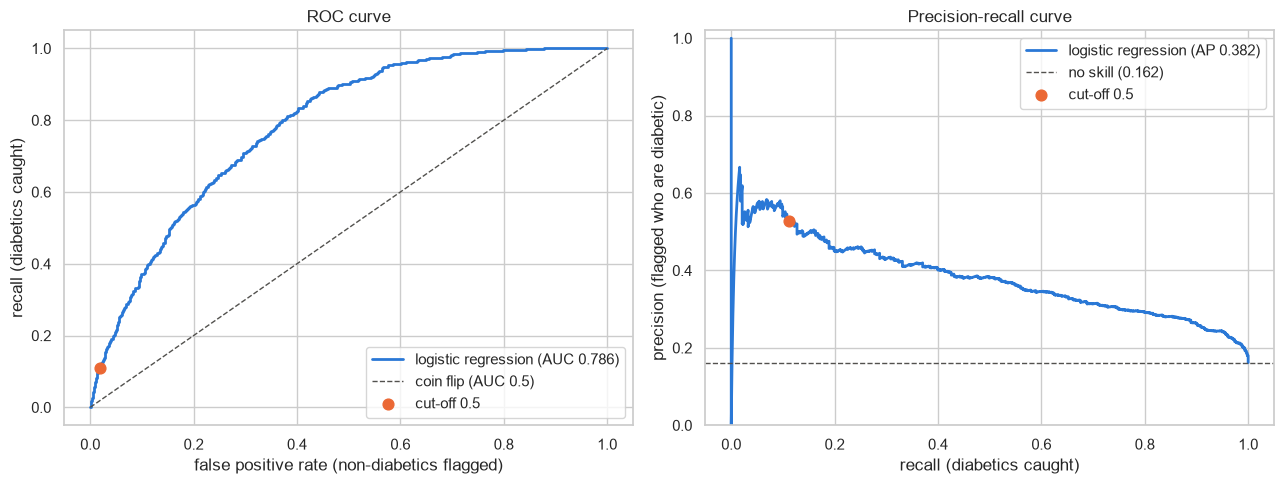

In [49]:
chosen_auc = roc_auc_score(y_train, chosen_oof)
chosen_ap = average_precision_score(y_train, chosen_oof)
diabetic_rate = y_train.mean()

fpr, tpr, _ = roc_curve(y_train, chosen_oof)
pr_precision, pr_recall, _ = precision_recall_curve(y_train, chosen_oof)

flagged = chosen_oof >= DEFAULT_CUTOFF
recall_at_default = flagged[y_train == 1].mean()
fpr_at_default = flagged[y_train == 0].mean()
precision_at_default = y_train[flagged].mean()

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 5))

ax_roc.plot(fpr, tpr, color=SINGLE_COLOR, linewidth=2, label=f"logistic regression (AUC {chosen_auc:.3f})")
ax_roc.plot([0, 1], [0, 1], color="#52514e", linestyle="--", linewidth=1, label="coin flip (AUC 0.5)")
ax_roc.scatter(fpr_at_default, recall_at_default, color=STATUS_COLORS["diabetic"], s=60, zorder=3, label=f"cut-off {DEFAULT_CUTOFF}")
ax_roc.set(title="ROC curve", xlabel="false positive rate (non-diabetics flagged)", ylabel="recall (diabetics caught)")
ax_roc.legend(loc="lower right")

ax_pr.plot(pr_recall, pr_precision, color=SINGLE_COLOR, linewidth=2, label=f"logistic regression (AP {chosen_ap:.3f})")
ax_pr.axhline(diabetic_rate, color="#52514e", linestyle="--", linewidth=1, label=f"no skill ({diabetic_rate:.3f})")
ax_pr.scatter(recall_at_default, precision_at_default, color=STATUS_COLORS["diabetic"], s=60, zorder=3, label=f"cut-off {DEFAULT_CUTOFF}")
ax_pr.set(title="Precision-recall curve", xlabel="recall (diabetics caught)", ylabel="precision (flagged who are diabetic)", ylim=(0, 1.02))
ax_pr.legend(loc="upper right")

plt.tight_layout()
plt.show()

### 7.3 Classification at the default 0.5 cut-off

`cutoff_metrics` turns probabilities into yes/no at a given cut-off and counts the four outcomes of the **confusion matrix**:

|  | Flagged | Not flagged |
|---|---|---|
| **Really diabetic** | caught (true positive) | **missed** (false negative) |
| **Not diabetic** | **false alarm** (false positive) | cleared (true negative) |

From those counts:
- **recall** = caught / all diabetics
- **precision** = caught / all flagged
- **specificity** = cleared / all non-diabetics (recall's mirror image, for the healthy group)
- **F1** = a single score that is high only when precision **and** recall are both decent (their harmonic mean)

8.2 reuses `cutoff_metrics` to compare cut-offs.

In [50]:
def cutoff_metrics(proba, cutoff, y=y_train):
    """Confusion-matrix counts and rates when everyone at or above the cut-off is flagged (y: true labels, train by default)."""
    predicted = (proba >= cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, predicted).ravel()
    return {
        "flagged": tp + fp, "caught": tp, "missed": fn, "false alarms": fp, "cleared": tn,
        "recall": tp / (tp + fn),
        "precision": tp / (tp + fp) if tp + fp else 0.0,
        "specificity": tn / (tn + fp),
        "f1": f1_score(y, predicted),
    }


default_metrics = cutoff_metrics(chosen_oof, DEFAULT_CUTOFF)
display(pd.DataFrame(
    [[default_metrics["caught"], default_metrics["missed"]], [default_metrics["false alarms"], default_metrics["cleared"]]],
    index=["really diabetic", "not diabetic"], columns=["flagged", "not flagged"],
))
pd.Series({k: default_metrics[k] for k in ["recall", "precision", "specificity", "f1"]}, name=f"cut-off {DEFAULT_CUTOFF}").round(3).to_frame()

,flagged,not flagged
really diabetic,68,545
not diabetic,61,3119


,cut-off 0.5
recall,0.111
precision,0.527
specificity,0.981
f1,0.183


### 7.4 Probability quality: Brier score and calibration

ROC-AUC only checks the **order** of people. A screening tool that reports "your risk is 30%" also needs the number itself to be right.

- **Brier score:** the average of (probability − outcome)², where the outcome is 1 for diabetic and 0 otherwise. **Lower is better.** The baseline is the dummy that tells everyone the diabetic rate (16.2%).
- **Calibration curve:** people are sorted by predicted probability into 10 equal-sized groups. For each group, the average **predicted** probability is plotted against the **actual** share who are diabetic. A well-calibrated model sits on the dashed diagonal: above it means it under-predicts, below means it over-predicts.

Brier score: model 0.117 | dummy 0.135 | 14% better than the dummy
Average predicted probability 0.162 vs real diabetic rate 0.162


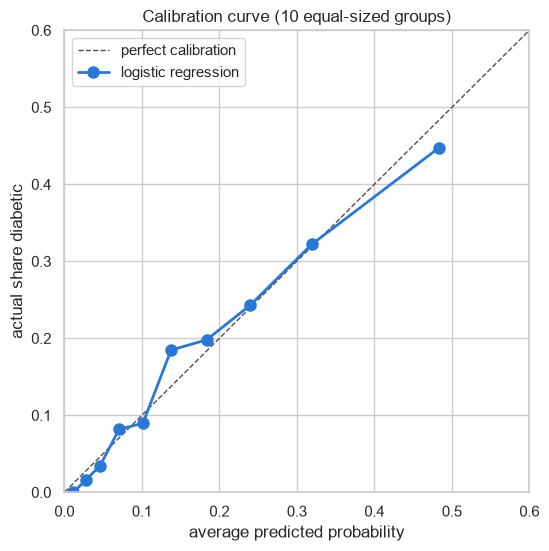

group,1,2,3,4,5,6,7,8,9,10
predicted,0.012,0.027,0.046,0.071,0.101,0.138,0.183,0.240,0.319,0.483
actual,0.000,0.016,0.034,0.082,0.089,0.185,0.198,0.243,0.322,0.447


In [51]:
CALIBRATION_BINS = 10

chosen_brier = brier_score_loss(y_train, chosen_oof)
dummy_brier = brier_score_loss(y_train, np.full(len(y_train), diabetic_rate))
print(f"Brier score: model {chosen_brier:.3f} | dummy {dummy_brier:.3f} | {1 - chosen_brier / dummy_brier:.0%} better than the dummy")
print(f"Average predicted probability {chosen_oof.mean():.3f} vs real diabetic rate {diabetic_rate:.3f}")

actual_rate, predicted_rate = calibration_curve(y_train, chosen_oof, n_bins=CALIBRATION_BINS, strategy="quantile")

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 0.6], [0, 0.6], color="#52514e", linestyle="--", linewidth=1, label="perfect calibration")
ax.plot(predicted_rate, actual_rate, color=SINGLE_COLOR, linewidth=2, marker="o", markersize=8, label="logistic regression")
ax.set(title="Calibration curve (10 equal-sized groups)", xlabel="average predicted probability", ylabel="actual share diabetic", xlim=(0, 0.6), ylim=(0, 0.6))
ax.legend(loc="upper left")
plt.show()

pd.DataFrame({"predicted": predicted_rate, "actual": actual_rate}, index=pd.RangeIndex(1, CALIBRATION_BINS + 1, name="group")).round(3).T

### 7.5 Report card

Every number for the chosen model in one place. This is the **baseline for Step 8**: calibration (8.1) and cut-off tuning (8.2) are judged against it.

In [52]:
report_card = pd.Series({
    "roc_auc": chosen_auc,
    "average_precision": chosen_ap,
    "brier": chosen_brier,
    "brier (dummy)": dummy_brier,
    "average probability": chosen_oof.mean(),
    "diabetic rate": diabetic_rate,
    **{f"{k} at {DEFAULT_CUTOFF}": default_metrics[k] for k in ["recall", "precision", "specificity", "f1"]},
}, name=CHOSEN_MODEL)
report_card.round(3).to_frame()

,logistic regression
roc_auc,0.786
average_precision,0.382
brier,0.117
brier (dummy),0.135
average probability,0.162
diabetic rate,0.162
recall at 0.5,0.111
precision at 0.5,0.527
specificity at 0.5,0.981
f1 at 0.5,0.183


### Step 7 summary

- **Ranking is solid and stable:** ROC-AUC 0.786 (folds 0.758–0.806), average precision 0.382, 2.4× the no-skill level of 0.162.
- **The 0.5 cut-off is the wrong place to decide:** it flags only 129 people, catching 68 of 613 diabetics (recall 0.11, F1 0.18). It sits at the far bottom-left of the ROC curve, where specificity is high (0.98) and recall is low.
- **The probabilities are already honest:** the average prediction equals the real rate (0.162), the calibration curve follows the diagonal across all 10 groups, and the Brier score is 14% better than the dummy's. Few people *should* get a probability above 50%, which is exactly why a 0.5 cut-off catches so few.

**Next, Step 8 (recalibration and optimization):** confirm calibration (8.1), choose a screening cut-off that catches most diabetics (8.2), test whether every feature group earns its place (8.3), and try the blood-pressure-medication experiment (8.4).

## Step 8 — Recalibration and optimization

Turns the chosen model into a finished screening tool by settling three questions, in this order:
1. **Which features?** Ablation (8.1) and the blood-pressure-medication experiment (8.2).
2. **Are the probabilities honest?** Calibration check (8.3).
3. **Where is the cut-off?** The screening cut-off (8.4).

Features come first because calibration and the cut-off depend on the model's probabilities, which change if the features change. Everything is still decided with CV on `train_df`.

### 8.1 Feature ablation

**Ablation** = remove one group of features, refit with CV, and see how much ROC-AUC drops:
- a **big drop** means the group carries information nothing else has
- **no drop** means other features already cover it

`build_pipeline` rebuilds the chosen pipeline (same fixed rules, imputing, scaling, encoding, and logistic regression with the chosen `C`) for any list of numeric features. An optional `extra_step` runs after the derived features, for experiments. `cv_auc` scores a pipeline with the same CV folds.

Changes smaller than the CV `std` (about 0.017, 6.4) are within noise.

In [53]:
assert CHOSEN_MODEL == "logistic regression", "build_pipeline assumes the chosen model is logistic regression"
CHOSEN_C = chosen_pipeline.get_params()["model__C"]


def build_pipeline(numeric_features, use_gender=True, extra_step=None):
    """The chosen pipeline, rebuilt for the given numeric features; extra_step runs after the derived features."""
    columns = [("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric_features)]
    if use_gender:
        columns.append(("gender", OneHotEncoder(drop="if_binary", sparse_output=False), ["gender"]))
    steps = [("fix", FunctionTransformer(fix_impossible_values)), ("derive", FunctionTransformer(add_derived_features))]
    if extra_step is not None:
        steps.append(("extra", FunctionTransformer(extra_step)))
    steps += [
        ("columns", ColumnTransformer(columns, verbose_feature_names_out=False)),
        ("model", LogisticRegression(max_iter=1000, C=CHOSEN_C)),
    ]
    return Pipeline(steps)


def cv_auc(pipeline, X=X_train):
    return cross_val_score(pipeline, X, y_train, cv=cv, scoring="roc_auc").mean()


FEATURE_GROUPS = {
    "age": ["age_years"],
    "pulse": ["pulse_60s"],
    "body size": ["bmi", "weight_kg", "waist_cm", "hip_cm", "arm_circumference_cm"],
    "shape ratios": ["waist_to_height", "waist_to_hip", "leg_to_height"],
    "blood pressure": ["mean_systolic", "mean_diastolic"],
    "limb lengths + height": ["upper_leg_length_cm", "upper_arm_length_cm", "height_cm"],
}

full_auc = cv_auc(build_pipeline(NUMERIC_MODEL_FEATURES))
ablation = {"(nothing: full model)": full_auc}
for group, cols in FEATURE_GROUPS.items():
    ablation[group] = cv_auc(build_pipeline([f for f in NUMERIC_MODEL_FEATURES if f not in cols]))
ablation["gender"] = cv_auc(build_pipeline(NUMERIC_MODEL_FEATURES, use_gender=False))

ablation = pd.DataFrame({"roc_auc": ablation})
ablation["change"] = ablation["roc_auc"] - full_auc
ablation.rename_axis("removed").sort_values("change").round(3)

,roc_auc,change
removed,,
age,0.750,-0.037
pulse,0.777,-0.009
body size,0.783,-0.004
shape ratios,0.784,-0.003
blood pressure,0.786,-0.001
limb lengths + height,0.786,-0.001
(nothing: full model),0.787,0.000
gender,0.787,0.000


### 8.1 check: two leftover ideas

Two ideas parked in earlier steps, tested the same way:
- **Log transform** of the skewed body measures (3.3): squeezes the long right tail of BMI, weight, waist and hip.
- **"Any body measure missing" flag** (3.2): a 0/1 column for people missing any body measurement. The Fisher tests found no single feature's missingness worth flagging; this tests them combined.

Each is added as `extra_step` on the full model.

In [54]:
SKEWED_FEATURES = ["bmi", "weight_kg", "waist_cm", "hip_cm"]
BODY_MEASURES = ["bmi", "weight_kg", "height_cm", "waist_cm", "hip_cm", "arm_circumference_cm", "upper_leg_length_cm", "upper_arm_length_cm"]


def log_skewed(df):
    df = df.copy()
    df[SKEWED_FEATURES] = np.log(df[SKEWED_FEATURES])
    return df


def add_body_missing_flag(df):
    df = df.copy()
    df["body_missing"] = df[BODY_MEASURES].isna().any(axis=1).astype(float)
    return df


extras = pd.DataFrame({"roc_auc": {
    "full model": full_auc,
    "log of skewed measures": cv_auc(build_pipeline(NUMERIC_MODEL_FEATURES, extra_step=log_skewed)),
    "missing-body-measure flag": cv_auc(build_pipeline(NUMERIC_MODEL_FEATURES + ["body_missing"], extra_step=add_body_missing_flag)),
}})
extras["change"] = extras["roc_auc"] - full_auc
extras.round(3)

,roc_auc,change
full model,0.787,0.000
log of skewed measures,0.787,0.001
missing-body-measure flag,0.786,-0.000


### 8.2 Experiment: blood pressure medication

3.9 found that BP medicine hides the BP–diabetes link, and that people on BP medicine are far more often diabetic (32% vs 10%). Two ways to use that, compared with the exam-only model:
- **Correct BP for medication:** add a typical treatment effect (+10 mmHg systolic, +5 diastolic) to the BP of people on medicine, estimating their untreated BP. The feature list stays the same.
- **`taking_bp_meds` as a feature:** the yes/no answer itself becomes a 17th input.

`taking_bp_meds` is a **questionnaire answer**, outside the exam-only scope set in Step 1, so it is used here **as an experiment only** (it stays `eda` in the catalog). The final model stays exam-only; the result is recorded as a finding.

In [55]:
BP_MED_SYSTOLIC_ADD = 10   # mmHg added to the systolic of people on BP medicine
BP_MED_DIASTOLIC_ADD = 5   # mmHg added to the diastolic

X_train_with_meds = train_df[FEATURES + ["taking_bp_meds"]]


def correct_bp_for_meds(df):
    df = df.copy()
    on_meds = df["taking_bp_meds"] == 1
    df.loc[on_meds, "mean_systolic"] += BP_MED_SYSTOLIC_ADD
    df.loc[on_meds, "mean_diastolic"] += BP_MED_DIASTOLIC_ADD
    return df


bp_meds = pd.DataFrame({"roc_auc": {
    "exam only (chosen model)": full_auc,
    "BP corrected for medicine": cv_auc(build_pipeline(NUMERIC_MODEL_FEATURES, extra_step=correct_bp_for_meds), X_train_with_meds),
    "taking_bp_meds as a feature": cv_auc(build_pipeline(NUMERIC_MODEL_FEATURES + ["taking_bp_meds"]), X_train_with_meds),
}})
bp_meds["change"] = bp_meds["roc_auc"] - full_auc
bp_meds.round(3)

,roc_auc,change
exam only (chosen model),0.787,0.000
BP corrected for medicine,0.786,-0.001
taking_bp_meds as a feature,0.796,0.010


### 8.3 🔁 Calibration check

Step 7 found the probabilities already honest. This cell checks whether recalibrating improves them anyway. `CalibratedClassifierCV` learns a mapping from the model's probabilities to better ones, with its own inner CV so it never calibrates on rows the model was fit on:
- **sigmoid:** a smooth S-shaped mapping (few settings, stable)
- **isotonic:** a flexible staircase (can fit any shape, needs more data)

Both are scored on the same out-of-fold basis as Step 7. If neither lowers the Brier score clearly, the final model stays uncalibrated: simpler, and nothing is lost.

In [56]:
def oof_probability(model):
    return cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]


calibration_versions = {"uncalibrated": chosen_oof}
for method in ["sigmoid", "isotonic"]:
    calibration_versions[method] = oof_probability(CalibratedClassifierCV(clone(chosen_pipeline), method=method, cv=N_FOLDS))

pd.DataFrame({
    name: {
        "brier": brier_score_loss(y_train, proba),
        "roc_auc": roc_auc_score(y_train, proba),
        "average probability": proba.mean(),
    }
    for name, proba in calibration_versions.items()
}).T.round(4)

,brier,roc_auc,average probability
uncalibrated,0.1167,0.7858,0.1620
sigmoid,0.1166,0.7858,0.1618
isotonic,0.1167,0.7833,0.1620


### 8.4 Screening cut-off

For screening, a **missed diabetic** (untreated disease) costs far more than a **false alarm** (one extra HbA1c blood test). So the rule is:

> **the highest cut-off that still catches at least `RECALL_TARGET` (80%) of diabetics**

A higher cut-off flags fewer people, so this is the cut-off that meets the recall goal with the fewest blood tests.

The chart shows recall, precision and specificity for every cut-off from 0.01 to 0.50 (from `chosen_oof`, via `cutoff_metrics` from 7.3); the dashed line is the chosen cut-off. The table shows the cut-offs around it.

The cut-off is chosen on the same out-of-fold probabilities it is scored on, so these numbers are slightly optimistic. The test set (Step 9) gives the honest result.

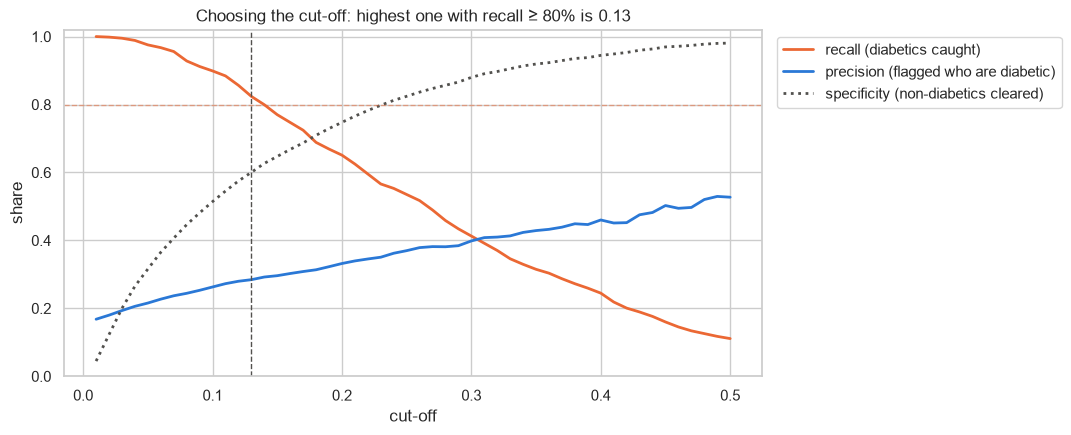

,flagged,flagged share,caught,missed,false alarms,recall,precision,specificity
cut-off,,,,,,,,
0.10,2096,0.553,551,62,1545,0.899,0.263,0.514
0.11,1988,0.524,542,71,1446,0.884,0.273,0.545
0.12,1877,0.495,525,88,1352,0.856,0.280,0.575
0.13,1776,0.468,505,108,1271,0.824,0.284,0.600
0.14,1677,0.442,490,123,1187,0.799,0.292,0.627
0.15,1594,0.420,472,141,1122,0.770,0.296,0.647
0.16,1514,0.399,458,155,1056,0.747,0.303,0.668


In [57]:
CANDIDATE_CUTOFFS = np.round(np.arange(0.01, 0.51, 0.01), 2)

cutoff_table = pd.DataFrame([cutoff_metrics(chosen_oof, c) for c in CANDIDATE_CUTOFFS], index=pd.Index(CANDIDATE_CUTOFFS, name="cut-off"))
cutoff_table["flagged share"] = cutoff_table["flagged"] / len(y_train)

SCREENING_CUTOFF = cutoff_table.index[cutoff_table["recall"] >= RECALL_TARGET].max()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(cutoff_table.index, cutoff_table["recall"], color=STATUS_COLORS["diabetic"], linewidth=2, label="recall (diabetics caught)")
ax.plot(cutoff_table.index, cutoff_table["precision"], color=SINGLE_COLOR, linewidth=2, label="precision (flagged who are diabetic)")
ax.plot(cutoff_table.index, cutoff_table["specificity"], color="#52514e", linewidth=2, linestyle=":", label="specificity (non-diabetics cleared)")
ax.axvline(SCREENING_CUTOFF, color="#52514e", linestyle="--", linewidth=1)
ax.axhline(RECALL_TARGET, color=STATUS_COLORS["diabetic"], linestyle="--", linewidth=1, alpha=0.5)
ax.set(title=f"Choosing the cut-off: highest one with recall ≥ {RECALL_TARGET:.0%} is {SCREENING_CUTOFF}", xlabel="cut-off", ylabel="share", ylim=(0, 1.02))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

near = cutoff_table.index[np.abs(cutoff_table.index - SCREENING_CUTOFF) <= 0.035]
cutoff_table.loc[near, ["flagged", "flagged share", "caught", "missed", "false alarms", "recall", "precision", "specificity"]].round(3)

### 8.5 The final setup

What Step 9 receives:
- **`final_pipeline`**: a fresh, unfitted copy of the chosen pipeline: exam-only features (16 columns), logistic regression with the chosen `C`, no class weights, no recalibration
- **`SCREENING_CUTOFF`**: people at or above it are referred for an HbA1c test

The table compares the expected CV performance at the screening cut-off with the default 0.5 cut-off from Step 7.

In [58]:
final_pipeline = clone(chosen_pipeline)

screening_metrics = cutoff_metrics(chosen_oof, SCREENING_CUTOFF)
SHOW = ["flagged", "caught", "missed", "false alarms", "recall", "precision", "specificity", "f1"]
print(f"Final model: {CHOSEN_MODEL}, C={CHOSEN_C}, {len(MODEL_FEATURES)} exam features | screening cut-off {SCREENING_CUTOFF}")
pd.DataFrame({
    f"default cut-off {DEFAULT_CUTOFF}": {k: default_metrics[k] for k in SHOW},
    f"screening cut-off {SCREENING_CUTOFF}": {k: screening_metrics[k] for k in SHOW},
}).round(3)

Final model: logistic regression, C=0.1, 16 exam features | screening cut-off 0.13


,default cut-off 0.5,screening cut-off 0.13
flagged,129.000,1776.000
caught,68.000,505.000
missed,545.000,108.000
false alarms,61.000,1271.000
recall,0.111,0.824
precision,0.527,0.284
specificity,0.981,0.600
f1,0.183,0.423


### Step 8 summary

- **Features (8.1):** only **age** (−0.037) and **pulse** (−0.009) are irreplaceable; every other group is covered by its neighbours, and removing it changes ROC-AUC by less than the CV noise. All 16 exam features are kept. The log transform and the missing-measure flag add nothing.
- **BP medication (8.2):** correcting BP for medicine adds nothing, but the yes/no answer `taking_bp_meds` as a feature lifts ROC-AUC by **+0.010** (0.787 → 0.796), the biggest gain after age. It is outside the exam-only scope, so the final model leaves it out; it is the first thing to add if the tool may ask one question.
- **Calibration (8.3):** sigmoid and isotonic recalibration don't improve the Brier score (0.1167), so the model stays uncalibrated.
- **Screening cut-off (8.4):** **0.13**, the highest cut-off that catches at least 80% of diabetics (0.14 just misses, at 79.9%).
- **Expected at 0.13 (CV):** catches **505 of 613** diabetics (recall 0.82) and refers 47% of adults for an HbA1c test, of whom about 28% are diabetic. At 0.5 it caught only 68.

**Next, Step 9 (final evaluation):** fit `final_pipeline` on all of `train_df`, open `test_df` once, score it at the 0.13 cut-off, check performance for women and men and for age groups, and save the model.

## Step 9 — Final evaluation

The sealed envelope opens. Every decision is already made: features (Step 4, 8.1), model and settings (6.4), no calibration (8.3), screening cut-off **0.13** (8.4). Step 9 changes none of them, whatever the test set shows; otherwise the test set would become one more round of tuning and its score would no longer be honest.

`test_df` (949 people, 153 diabetic) has not been touched since the split in 2.6.

### 9.1 Refit on the full training set

During CV each model learned from 4/5 of `train_df`. The final model learns from **all** of it: `final_pipeline.fit` refits every stage (medians, scaling, encoding, weights) on the 3,793 training people. Nothing from `test_df` is used.

In [59]:
final_model = final_pipeline.fit(X_train, y_train)

print(f"Fitted on {len(X_train):,} people; {final_model[-1].coef_.shape[1]} model columns; intercept {final_model[-1].intercept_[0]:.3f}")

Fitted on 3,793 people; 16 model columns; intercept -2.132


### 9.2 Score the test set, once

`final_model` turns each test person's raw exam features into a probability, using medians and scales learned from the training set only, exactly as it would for a new patient. Then everyone at or above `SCREENING_CUTOFF` is flagged.

The table puts the test results next to the CV estimates from `train_df` (Steps 7–8). Close numbers mean the CV estimates were honest; the test column is the result to report.

In [60]:
X_test = test_df[FEATURES]
y_test = test_df[TARGET]
test_proba = final_model.predict_proba(X_test)[:, 1]

test_brier = brier_score_loss(y_test, test_proba)
test_dummy_brier = brier_score_loss(y_test, np.full(len(y_test), diabetic_rate))
test_metrics = cutoff_metrics(test_proba, SCREENING_CUTOFF, y=y_test)

RESULT_ROWS = ["roc_auc", "average_precision", "brier", "brier (dummy)", "average probability", "diabetic rate",
               "flagged share", "recall", "precision", "specificity", "f1"]
results = pd.DataFrame({
    "CV on train (expected)": {
        "roc_auc": chosen_auc, "average_precision": chosen_ap, "brier": chosen_brier, "brier (dummy)": dummy_brier,
        "average probability": chosen_oof.mean(), "diabetic rate": diabetic_rate,
        "flagged share": screening_metrics["flagged"] / len(y_train),
        **{k: screening_metrics[k] for k in ["recall", "precision", "specificity", "f1"]},
    },
    "test (final)": {
        "roc_auc": roc_auc_score(y_test, test_proba), "average_precision": average_precision_score(y_test, test_proba),
        "brier": test_brier, "brier (dummy)": test_dummy_brier,
        "average probability": test_proba.mean(), "diabetic rate": y_test.mean(),
        "flagged share": test_metrics["flagged"] / len(y_test),
        **{k: test_metrics[k] for k in ["recall", "precision", "specificity", "f1"]},
    },
}).loc[RESULT_ROWS]
display(results.round(3))

pd.DataFrame(
    [[test_metrics["caught"], test_metrics["missed"]], [test_metrics["false alarms"], test_metrics["cleared"]]],
    index=["really diabetic", "not diabetic"], columns=[f"flagged (≥ {SCREENING_CUTOFF})", "not flagged"],
)

,CV on train (expected),test (final)
roc_auc,0.786,0.785
average_precision,0.382,0.363
brier,0.117,0.118
brier (dummy),0.135,0.135
average probability,0.162,0.165
diabetic rate,0.162,0.161
flagged share,0.468,0.493
recall,0.824,0.889
precision,0.284,0.291
specificity,0.600,0.583


,flagged (≥ 0.13),not flagged
really diabetic,136,17
not diabetic,332,464


### 9.3 Slice checks: does it work for everyone?

A good overall score can hide a group the model serves badly. This cell scores the test set separately for women and men and for the age bands from 3.6, at the screening cut-off.

**Read small groups with care:** the test set has only 153 diabetics, so some age bands contain just a handful. Their recall can swing a lot by chance, and ROC-AUC is left blank when a group has no diabetics at all.

In [61]:
test_age_group = pd.cut(test_df["age_years"], bins=AGE_BANDS, labels=AGE_LABELS)
test_slices = {"everyone": np.ones(len(test_df), dtype=bool)}
for sex in ["female", "male"]:
    test_slices[sex] = (test_df["gender"] == sex).to_numpy()
for band in AGE_LABELS:
    test_slices[f"age {band}"] = (test_age_group == band).to_numpy()


def slice_metrics(mask):
    y, proba = y_test.to_numpy()[mask], test_proba[mask]
    flagged = proba >= SCREENING_CUTOFF
    return {
        "people": mask.sum(),
        "diabetic": y.sum(),
        "roc_auc": roc_auc_score(y, proba) if 0 < y.sum() < len(y) else np.nan,
        "flagged share": flagged.mean(),
        "recall": flagged[y == 1].mean() if y.sum() else np.nan,
        "precision": y[flagged].mean() if flagged.any() else np.nan,
    }


pd.DataFrame({name: slice_metrics(mask) for name, mask in test_slices.items()}).T.round(3)

,people,diabetic,roc_auc,flagged share,recall,precision
everyone,949.0,153.0,0.785,0.493,0.889,0.291
female,504.0,68.0,0.760,0.494,0.868,0.237
male,445.0,85.0,0.809,0.492,0.906,0.352
age 20-34,221.0,11.0,0.922,0.054,0.545,0.500
age 35-44,127.0,6.0,0.891,0.197,1.000,0.240
age 45-54,152.0,21.0,0.701,0.467,0.810,0.239
age 55-64,191.0,43.0,0.662,0.665,0.884,0.299
age 65-80,258.0,72.0,0.675,0.903,0.958,0.296


### 9.4 Save the final model

`joblib` writes the fitted pipeline to a file, and a small JSON file records how to use it: the screening cut-off, the input columns and the library versions. The cell then **reloads** the file and checks it gives exactly the same probabilities.

**One caveat:** the pipeline's first two stages call `fix_impossible_values` and `add_derived_features`, which are defined in this notebook. The saved file stores only their **names**, so loading it elsewhere requires those two functions to be defined first (or moved into a `.py` module and imported).

In [62]:
import sklearn

MODEL_PATH = Path("diabetes_screening_model.joblib")
MODEL_INFO_PATH = Path("diabetes_screening_model.json")

joblib.dump(final_model, MODEL_PATH)
MODEL_INFO_PATH.write_text(json.dumps({
    "model": CHOSEN_MODEL,
    "settings": {k.removeprefix("model__"): v for k, v in searches[CHOSEN_MODEL].best_params_.items()},
    "screening_cutoff": float(SCREENING_CUTOFF),
    "recall_target": RECALL_TARGET,
    "input_features": FEATURES,
    "test_roc_auc": round(float(results.loc["roc_auc", "test (final)"]), 3),
    "test_recall": round(float(test_metrics["recall"]), 3),
    "scikit_learn_version": sklearn.__version__,
    "pandas_version": pd.__version__,
}, indent=2))

reloaded = joblib.load(MODEL_PATH)
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], test_proba), "reloaded model gives different probabilities"
print(f"Saved {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1024:.0f} KB) and {MODEL_INFO_PATH}; reload check passed")

Saved diabetes_screening_model.joblib (8 KB) and diabetes_screening_model.json; reload check passed


### 9.5 Are the false alarms really false?

The model never sees blood tests, but the cohort has an HbA1c result for everyone (1.7). Here it is used **only to judge** the screening decisions, never as a feature.

The printed line gives the **referral rate**: the share of all people sent for a blood test. Then two tables for each set (test, and train out-of-fold for comparison):
1. **By outcome** at the screening cut-off (caught, missed, false alarm, cleared): the HbA1c median, its middle 50%, and the share in the **prediabetes** range (5.7–6.4%).
2. **Against a baseline.** Prediabetes is common, so some false alarms would be prediabetic even if people were sent for testing at random. This table compares everyone **referred** with **everyone** (what a random referral would find) and with everyone **not referred**:
   - `abnormal blood sugar`: diabetic, or non-diabetic with HbA1c 5.7–6.4
   - `prediabetic among non-diabetics`: the false-alarm question, with its baseline

Some caught or missed people have a normal HbA1c: they are **diagnosed** diabetics whose treatment has brought it down (the target counts a diagnosis, 1.5).

In [63]:
hba1c_by_person = merged.set_index("person_id")["hba1c_percent"]


def hba1c_by_outcome(df, y, proba):
    """HbA1c summary for caught, missed, false-alarm and cleared people at the screening cut-off."""
    hba1c = df["person_id"].map(hba1c_by_person).to_numpy()
    y = np.asarray(y)
    flagged = proba >= SCREENING_CUTOFF
    outcomes = {
        "caught": flagged & (y == 1), "missed": ~flagged & (y == 1),
        "false alarm": flagged & (y == 0), "cleared": ~flagged & (y == 0),
    }
    summary = pd.DataFrame({
        name: {
            "people": mask.sum(),
            "median hba1c": np.median(hba1c[mask]),
            "q25": np.quantile(hba1c[mask], 0.25),
            "q75": np.quantile(hba1c[mask], 0.75),
            "prediabetes share": ((hba1c[mask] >= PREDIABETES_A1C) & (hba1c[mask] < HBA1C_DIABETES_CUTOFF)).mean(),
        }
        for name, mask in outcomes.items()
    }).T
    return summary


def referral_vs_baseline(df, y, proba):
    """Abnormal blood sugar among referred people vs everyone (a random referral) vs people not referred."""
    hba1c = df["person_id"].map(hba1c_by_person).to_numpy()
    y = np.asarray(y)
    flagged = proba >= SCREENING_CUTOFF
    prediabetic = (y == 0) & (hba1c >= PREDIABETES_A1C)   # non-diabetics never reach 6.5 (1.5)
    abnormal = (y == 1) | prediabetic
    groups = {"referred": flagged, "everyone (random pick)": np.ones(len(y), dtype=bool), "not referred": ~flagged}
    return pd.DataFrame({
        name: {
            "people": mask.sum(),
            "abnormal blood sugar": abnormal[mask].mean(),
            "diabetic": y[mask].mean(),
            "prediabetic among non-diabetics": prediabetic[mask & (y == 0)].sum() / (mask & (y == 0)).sum(),
        }
        for name, mask in groups.items()
    }).T


for name, (df, y, proba) in {"test": (test_df, y_test, test_proba), "train (out-of-fold)": (train_df, y_train, chosen_oof)}.items():
    print(f"{name}: {(proba >= SCREENING_CUTOFF).sum():,} of {len(proba):,} people referred for a blood test ({(proba >= SCREENING_CUTOFF).mean():.0%})")
    display(hba1c_by_outcome(df, y, proba).round(3))
    display(referral_vs_baseline(df, y, proba).round(3))

test: 468 of 949 people referred for a blood test (49%)


,people,median hba1c,q25,q75,prediabetes share
caught,136.0,6.8,6.5,7.6,0.169
missed,17.0,7.0,6.6,8.0,0.176
false alarm,332.0,5.7,5.4,5.9,0.536
cleared,464.0,5.4,5.2,5.6,0.209


,people,abnormal blood sugar,diabetic,prediabetic among non-diabetics
referred,468.0,0.671,0.291,0.536
everyone (random pick),949.0,0.451,0.161,0.345
not referred,481.0,0.237,0.035,0.209


train (out-of-fold): 1,776 of 3,793 people referred for a blood test (47%)


,people,median hba1c,q25,q75,prediabetes share
caught,505.0,6.8,6.3,7.5,0.251
missed,108.0,6.7,6.2,7.6,0.213
false alarm,1271.0,5.7,5.4,5.9,0.505
cleared,1909.0,5.4,5.1,5.6,0.223


,people,abnormal blood sugar,diabetic,prediabetic among non-diabetics
referred,1776.0,0.646,0.284,0.505
everyone (random pick),3793.0,0.443,0.162,0.336
not referred,2017.0,0.264,0.054,0.223


### Step 9 summary: final results

**The test set confirms the CV estimates.** On 949 people the model had never seen:

| | CV on train (expected) | Test (final) |
|---|---|---|
| ROC-AUC | 0.786 | **0.785** |
| Recall at 0.13 | 0.82 | **0.89** (136 of 153 diabetics caught) |
| Precision at 0.13 | 0.28 | **0.29** |
| People referred | 47% | 49% |
| Average probability vs real rate | 0.162 vs 0.162 | 0.165 vs 0.161 |

Ranking and calibration held almost exactly. Recall came out higher than expected; with 153 test diabetics, one person is worth 0.7 percentage points, so this is within chance.

**Slice checks (9.3):**
- **Sex:** it works for both, better for men (ROC-AUC 0.81, precision 0.35) than women (0.76, 0.24).
- **Age is doing much of the work.** The model refers 90% of people aged 65–80 and only 5% of those aged 20–34. Within an age band, ROC-AUC drops to 0.66–0.70 for people over 45: telling apart two people of the *same* age is much harder than the overall 0.785 suggests.
- **Young diabetics are the weak spot:** only 6 of 11 diabetics aged 20–34 were caught (small numbers, but consistent with 3.6).

**False alarms are often not false, but the referral rate is high (9.5):**

| Test set | Referred | Everyone (random pick) | Not referred |
|---|---|---|---|
| People | 468 (49%) | 949 | 481 |
| Abnormal blood sugar | **67%** | 45% | 24% |
| Diabetic | 29% | 16% | 3.5% |
| Prediabetic among the non-diabetics | **54%** | 34% | 21% |

- The false alarms have a median HbA1c of **5.7%**, the start of the prediabetes range. 54% of them are prediabetic, against a baseline of 34% for all non-diabetics: about **1.6×** the rate a random referral would find.
- **The honest caveat: prediabetes and diabetes together are common** (45% of these adults). So even a random pick would find abnormal blood sugar in almost half of the people tested. The model raises that to two thirds, a real but moderate gain.
- **The price is the referral rate:** to catch about 9 in 10 diabetics, the model sends **about half of all adults** (49%) for a blood test. That is high for a screening step, and it is the direct cost of using no blood test and a cut-off chosen for 80% recall. Raising `RECALL_TARGET`'s cut-off (8.4) refers fewer people but misses more diabetics.

**Saved:** `diabetes_screening_model.joblib` (the fitted pipeline) and `diabetes_screening_model.json` (cut-off, inputs, versions).

**In one line:** using only a tape measure, a scale, a blood pressure cuff, age and sex, the model catches about 9 in 10 diabetics, but only by sending about half of adults for an HbA1c test; two thirds of them have diabetes or prediabetes, against 45% for a random pick.